# Magnetic chain on an s-wave superconductor (MSH chain) with TensorBinding

This notebook builds the Bogoliubov–de Gennes (BdG) Hamiltonian of a single magnetic chain on an
s-wave superconductor as a **matrix product operator (MPO)** using `TensorBinding.jl` and checks it against a dense
reference. It then uses tensor-network methods for:

- the **local density of states (LDOS)** at four snapshots of the spin ramp (fully topological to fully trivial), by exact diagonalization and with TensorBinding's KPM routine `get_ldos_spatial`;
- the **Majorana zero modes** and the ordinary fermion they form (DMRG on $H^2$, localization, self-conjugacy, pairing);
- the **charge difference** $\Delta Q$ and density difference $\delta n(x)$ between the logical states $|0\rangle$ and $|1\rangle$;
- the **time-dependent** transport of the Majoranas by rotating spins with the CZ project's ramp protocol (TDVP), including $\Delta Q(t)$, $\delta n(x,t)$ and the non-adiabatic error.

Every tensor-network result is checked against exact diagonalization or exact time evolution of the same model.

It collects `msh_chain.jl` (Hamiltonian builder), `msh_chain_ldos.jl` (LDOS), `msh_chain_majorana.jl` (zero modes and pairing),
`msh_chain_charge.jl` (static charge difference), and `msh_chain_ramp.jl` (time-dependent ramp)
into one place.

**Contents**
1. Setup
2. Model and conventions
3. Building blocks: Pauli matrices, spin texture, exact diagonal MPOs
4. The Hamiltonian builder `msh_chain`
5. Dense helpers and validation
6. Rotation sweep: switching phases with the spins
7. LDOS
8. LDOS with TensorBinding's KPM routine
9. Majorana zero modes and the fermion mode
10. Charge difference between the logical states
11. Time-dependent ramp: moving the Majoranas by rotating spins
12. How to adapt this notebook

**Runtime.** Sections 1–9 take a few minutes. Sections 8a, 10 and 11 save their results to `.jls` files next to the notebook
and load them on later runs. Their first runs take about 30, 10 and 4 minutes.

## 1. Setup

Load the packages and the local copy of TensorBinding (`src/TensorBinding.jl` in this folder).
If you move the notebook, change `TB_SRC` to point at your TensorBinding source.

In [1]:
using LinearAlgebra, ITensors, ITensorMPS, Printf, Plots
using TensorBinding
const TB = TensorBinding

TensorBinding

## 2. Model and conventions

**Particle block** (the 1D slice of the kwant CZ model: `chain` onsite + `hop_x` hopping):

$$
H_0 = \sum_n c_n^\dagger\left(-\mu + J\,\mathbf S_n\cdot\boldsymbol\sigma\right)c_n
    + \sum_n \left[c_{n+1}^\dagger\left(-t + i\alpha\,\sigma_y\right)c_n + \text{h.c.}\right]
$$

with constant chemical potential $\mu$, exchange $J$, Rashba spin–orbit coupling $\alpha$, open boundaries,
and on-site singlet s-wave pairing $\Delta\,(c_\uparrow^\dagger c_\downarrow^\dagger - c_\downarrow^\dagger c_\uparrow^\dagger)$.

**Nambu basis** $(c_\uparrow, c_\downarrow, c_\uparrow^\dagger, c_\downarrow^\dagger)$, the basis implied by TensorBinding's $i\sigma_y$ pairing:

$$
H_{\rm BdG} = \begin{pmatrix} H_0 & \Delta\, i\sigma_y \\ (\Delta\, i\sigma_y)^\dagger & -H_0^* \end{pmatrix}.
$$

This differs from the python notebook's $(c_\uparrow, c_\downarrow, c_\downarrow^\dagger, -c_\uparrow^\dagger)$ basis. Spectra and LDOS are basis-independent.

**MPO site ordering:** `[nambu; spin; pos₁ … pos_L]`, with the chain length $N = 2^L$ encoded in $L$ position qubits
(`pos₁` = most significant bit). In a dense matrix, the row index is `kron(nambu, spin, position)`.

**Spin texture (horizontal chain, φ = π/2):**

$$
\mathbf S_n = (\cos\phi\sin\theta_n,\ \sin\phi\sin\theta_n,\ \cos\theta_n),\qquad
\theta_n = (-1)^n\,\tfrac{\pi}{2}\,f(n)
$$

| `f(n)` | spins | phase at μ = −7 |
|---|---|---|
| 0 | all along $+\hat z$ (ferromagnetic, out of plane) | topological (Majorana end modes) |
| 1 | alternating $\pm\hat y$ (antiferromagnetic, in plane) | trivial (gapped, no end modes) |

The chemical potential stays fixed. The phase is switched only by rotating the spins through `f`.

> **Why the BdG is assembled by hand.** The high-level `add_superconductivity!` builds the hole block as $\tau_z\otimes H_0$,
> which is wrong whenever $H_0$ has imaginary parts (the $\sigma_y$ exchange component). `add_soc!(:rashba)` uses periodic shift
> operators, so it adds a bond between the chain ends. Both break the comparison with the kwant model, so `msh_chain`
> uses TensorBinding's low-level pieces instead.

## 3. Building blocks

### 3a. Pauli matrices and the spin texture

`spin_texture(f; φ)` returns a function `n -> (Sx, Sy, Sz)` for the 0-indexed site `n`, following the CZ convention above.
`f` is any function of the site index with values in $[0,1]$, so you can make uniform rotations (`n -> 0.3`) or domains
(`n -> 16 ≤ n < 48 ? 0.0 : 1.0`). A time-dependent protocol is `n -> f(n, t)`.

In [2]:
#Pauli matrices
const σ0 = ComplexF64[1 0; 0 1];   const σx = ComplexF64[0 1; 1 0]
const σy = ComplexF64[0 -im; im 0]; const σz = ComplexF64[1 0; 0 -1]

#spin texture; n is the 0-indexed chain site, f(n) ∈ [0, 1]
spin_texture(f; φ=π/2) = n -> (θ = (-1)^n * (π/2) * f(n);
                               (cos(φ)*sin(θ), sin(φ)*sin(θ), cos(θ)))

spin_texture (generic function with 1 method)

### 3b. Exact diagonal MPOs

`diag_mpo_exact(v, pos)` turns a length-$2^L$ vector `v` into the diagonal MPO $\mathrm{diag}(v)$ on the position qubits `pos`.
It compresses `v` with an exact tensor-train SVD (`MPS(A, pos)`) and then copies each MPS tensor onto the diagonal of an MPO tensor.

It is used for the site-dependent exchange field. TensorBinding's own `add_onsite!` / `get_diagonal_mpo` use
quantics TCI, which can silently drop sites of **narrow or step-like profiles** (for example sharp domain walls) at $L \ge 8$.
The exact TT-SVD never does, at the cost of an $O(2^L)$ vector. That's fine up to $L \approx 20$.

In [3]:
# Exact diagonal MPO diag(v) on the position qubits (TT-SVD, no QTCI).
# sites[1] is the most significant bit, so reverse Julia's column-major order.
function diag_mpo_exact(v::AbstractVector, pos; cutoff=1e-14)
    L = length(pos)
    A = permutedims(reshape(ComplexF64.(v), ntuple(_ -> 2, L)), L:-1:1)
    ψ = MPS(A, pos; cutoff=cutoff)
    W = MPO(pos, "Id")
    for k in 1:L
        s = pos[k]
        δ = ITensor(ComplexF64, s, s', dag(s''))   # δ(s, s', s'') copies the amplitude onto the diagonal
        for j in 1:2; δ[s => j, s' => j, s'' => j] = 1; end
        W[k] = ψ[k] * δ
        W[k] = replaceprime(W[k], 2 => 0; tags=tags(s))
    end
    return W
end

diag_mpo_exact (generic function with 1 method)

## 4. The Hamiltonian builder `msh_chain`

```julia
HB, sites = msh_chain(L, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8, φ=π/2)
```

- `L`: number of position qubits; the chain has $N = 2^L$ sites.
- `f`: spin-rotation profile `f(n)` (see 3a).
- Keyword arguments: model parameters. The defaults are the CZ-project values.
- Returns the BdG MPO `HB` and its site indices `sites = [nambu; spin; pos...]`.

Steps inside:
1. `get_Hamiltonian("chain_1d", -t)` gives the hopping $-t$, and `add_onsite!(H, -μ)` gives the constant chemical potential.
2. `add_spin!` adds the spin site (spin-degenerate so far).
3. **Rashba** $\alpha\, i\sigma_y\otimes(K_u - K_d)$ uses **open-boundary** shift operators `shift_pair_mpos(pos, 1; cyclic=false)`.
   Here $K_u$ is the forward shift $c^\dagger_{n+1}c_n$.
4. **Exchange** $J\,\mathbf S_n\cdot\boldsymbol\sigma$: one exact diagonal MPO per spin component, attached with the full Pauli
   matrix. TensorBinding's `:Sx/:Sy/:Sz` are $\sigma/2$, so explicit matrices are used here.
5. **BdG assembly**: $P_p\otimes H_0 + P_h\otimes(-H_0^*) + \tau_+\otimes \Delta\, i\sigma_y + \tau_-\otimes(\Delta\, i\sigma_y)^\dagger$.
   On a plain MPO, `dag` is the elementwise complex conjugate.

The MPO bond dimension stays small (5–8 for the textures below), so the construction itself scales to large $L$.

In [4]:
"""
    msh_chain(L, f; t, μ, α, Δ, J, φ) -> (H_BdG::MPO, sites)

Sites are [nambu; spin; pos...].  `f(n)` (n = 0 … 2^L−1) is the rotation
fraction of the CZ protocol: 0 = topological (S ∥ ẑ), 1 = trivial (AFM ∥ ±ŷ).
"""
function msh_chain(L, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8, φ=π/2, cutoff=1e-12)
    N = 2^L
    H = TB.get_Hamiltonian("chain_1d", -t; L=L)
    TB.add_onsite!(H, -μ)                        # constant μ along the chain
    TB.add_spin!(H)
    pos = TB._pos_sites(H); ss = H.spin_s

    # Rashba with open boundaries (add_soc! wraps around the chain ends)
    Ku, Kd = TB.shift_pair_mpos(pos, 1; cyclic=false)
    H0 = +(H.mpo, TB.prepend_spin(α*Ku, ss, :iSy), TB.prepend_spin(-α*Kd, ss, :iSy); cutoff)

    # Exchange J S_n·σ, one exact diagonal MPO per spin component
    S = spin_texture(f; φ)
    for (k, σ) in enumerate((σx, σy, σz))
        v = [J * S(n)[k] for n in 0:N-1]
        maximum(abs, v) > 1e-14 || continue
        H0 = +(H0, TB.prepend_spin(diag_mpo_exact(v, pos), ss, σ); cutoff)
    end

    # BdG: particle H0, hole −H0*, singlet s-wave pairing
    ns  = TB.nambu_index()
    Hp  = TB.prepend_spin(Δ * MPO(pos, "Id"), ss, :iSy)
    Hpd = swapprime(dag(Hp), 0, 1)
    HB  = +(TB.prepend_nambu(H0, ns, :Pp), TB.prepend_nambu(-1.0*dag(H0), ns, :Ph),
            TB.prepend_nambu(Hp, ns, :tp), TB.prepend_nambu(Hpd, ns, :tm); cutoff)
    return HB, [ns; ss; pos]
end

msh_chain (generic function with 1 method)

**Example:** a 64-site chain ($L=6$) with all spins along $\hat z$:

In [5]:
HB, sites = msh_chain(6, n -> 0.0)
println("sites: ", length(sites), " (nambu, spin, ", length(sites) - 2, " position qubits)")
println("max MPO bond dimension: ", maxlinkdim(HB))

sites: 8 (nambu, spin, 6 position qubits)
max MPO bond dimension: 5


## 5. Dense helpers and validation

These two functions are for **small systems only** (dense dimension $4N$; practical up to $L \approx 7$).

- `dense(mpo, sites)` contracts the MPO into a dense matrix, ordered `kron(nambu, spin, position)`.
  It is much faster than `TB.get_matrix`, which applies the MPO to every basis state.
- `reference(L, f; ...)` builds the same BdG matrix directly from the model definition, with no MPOs. It is an independent check.

In [6]:
# Fast dense matrix for small systems: row/col index big-endian over `sites`.
function dense(mpo, sites)
    T = ITensors.@disable_warn_order prod(mpo)
    D = prod(dim.(sites))
    return reshape(Array(T, reverse(prime.(sites))..., reverse(sites)...), D, D)
end

# Dense reference built directly from the model definition
function reference(L, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8, φ=π/2)
    N = 2^L; S = spin_texture(f; φ)
    T  = diagm(-1 => ones(N-1))                      # T[n+1, n] = 1 : c†_{n+1} c_n, open BC
    H0 = kron(σ0, -μ * I(N)) .+ 0im
    for n in 0:N-1
        P = zeros(N, N); P[n+1, n+1] = 1
        H0 += kron(J * sum(S(n)[k] * m for (k, m) in enumerate((σx, σy, σz))), P)
    end
    hop = kron(-t*σ0 + im*α*σy, T)
    H0 += hop + hop'
    D = kron(Δ * im*σy, I(N))
    return [H0 D; D' -conj(H0)]
end

reference (generic function with 1 method)

**Validation.** For three spin textures, compare the MPO to the reference and check particle–hole symmetry
$C H^* C = -H$ with $C = \tau_x$. Errors should be at round-off ($\sim 10^{-12}$).
The last column shows the two smallest $|E|$: a value near zero followed by a gap means a Majorana pair.

In [7]:
let L = 6, N = 2^L
    C = kron(σx, kron(σ0, I(N)))                  # PH: C H* C = −H
    cases = [("all f=0  (FM ẑ)",               n -> 0.0),
             ("all f=1  (AFM ±ŷ)",             n -> 1.0),
             ("f=0 on middle half, 1 outside", n -> N÷4 ≤ n < 3N÷4 ? 0.0 : 1.0)]
    println("L=$L (N=$N), μ = −7 fixed")
    for (name, f) in cases
        HB, sites = msh_chain(L, f)
        M = dense(HB, sites); R = reference(L, f)
        E = sort(abs.(eigvals(Hermitian((M + M')/2))))
        @printf("%-32s ‖H−H_ref‖=%.1e  PH err=%.1e  χ=%d  |E|₁,₃ = %.2e, %.3f\n",
                name, norm(M - R), norm(C*conj(M)*C + M), maxlinkdim(HB), E[1], E[3])
    end
end

L=6 (N=64), μ = −7 fixed
all f=0  (FM ẑ)                  ‖H−H_ref‖=3.3e-12  PH err=0.0e+00  χ=5  |E|₁,₃ = 1.31e-14, 0.255
all f=1  (AFM ±ŷ)                ‖H−H_ref‖=1.9e-12  PH err=0.0e+00  χ=6  |E|₁,₃ = 1.38e+00, 1.378
f=0 on middle half, 1 outside    ‖H−H_ref‖=1.4e-12  PH err=0.0e+00  χ=8  |E|₁,₃ = 3.32e-08, 0.259


## 6. Rotation sweep: switching phases with the spins

Rotate every spin by the same fraction `f` from 0 (along $\hat z$) to 1 (alternating $\pm\hat y$) at fixed $\mu=-7$.
$|E|_1$ is the lowest eigenvalue, the Majorana pair when it exists. $|E|_3$ is the next one, the bulk gap edge.
The zero mode survives up to $f\approx 0.3$. The gap nearly closes at $f\approx0.35$ (the phase transition), and the chain is trivially gapped beyond that.

In [8]:
let L = 6
    for f in 0:0.1:1
        HB, sites = msh_chain(L, n -> f)
        E = sort(abs.(eigvals(Hermitian(dense(HB, sites)))))
        @printf("  f = %.1f   |E|₁ = %.3e   |E|₃ = %.3f\n", f, E[1], E[3])
    end
end

  f = 0.0   |E|₁ = 1.269e-14   |E|₃ = 0.255
  f = 0.1   |E|₁ = 7.401e-13   |E|₃ = 0.235
  f = 0.2   |E|₁ = 8.215e-09   |E|₃ = 0.177
  f = 0.3   |E|₁ = 2.236e-04   |E|₃ = 0.085
  f = 0.4   |E|₁ = 7.031e-02   |E|₃ = 0.094
  f = 0.5   |E|₁ = 2.352e-01   |E|₃ = 0.246
  f = 0.6   |E|₁ = 4.342e-01   |E|₃ = 0.441
  f = 0.7   |E|₁ = 6.605e-01   |E|₃ = 0.665
  f = 0.8   |E|₁ = 9.089e-01   |E|₃ = 0.912
  f = 0.9   |E|₁ = 1.174e+00   |E|₃ = 1.176
  f = 1.0   |E|₁ = 1.378e+00   |E|₃ = 1.378


## 7. Local density of states

From the exact eigenpairs $(E_k, \psi_k)$ of the densified MPO, with $\psi_k = (u_k, v_k)$ split into particle and hole parts:

$$
A_p(n,\omega) = \sum_k \sum_{\sigma} |u_k(n,\sigma)|^2\,\delta_\eta(\omega - E_k),\qquad
A_h(n,\omega) = \sum_k \sum_{\sigma} |v_k(n,\sigma)|^2\,\delta_\eta(\omega - E_k),
$$

with Lorentzian broadening $\delta_\eta(x) = (\eta/\pi)/(x^2+\eta^2)$. Both are **summed over spin** ↑ + ↓.
Particle–hole symmetry gives $A_h(n,\omega) = A_p(n,-\omega)$, and the total LDOS is $A_p + A_h$.

`ldos(L, f; η, ω, model...)` returns `(A_p, A_h)`, each of size `length(ω) × N`. Extra keyword arguments go to `msh_chain`,
for example `ldos(6, n -> 0.0; J=5.0)`.

**Note on the asymmetry.** The particle LDOS is concentrated at $\omega>0$. With $J=5.8$, the lower exchange-split band spans
$\xi\in[-0.8, 3.2]$, so $\mu=-7$ sits only 0.8 above its bottom. Almost all normal-state states are empty, and empty states put their
particle weight at positive energy.

In [9]:
function ldos(L, f; η=0.03, ω=range(-3, 3; length=601), model...)
    N = 2^L
    HB, sites = msh_chain(L, f; model...)
    E, U = eigen(Hermitian(dense(HB, sites)))
    # dense index = (nambu-1)·2N + (spin-1)·N + n ; nambu 1 = particle, 2 = hole
    wp = abs2.(U[1:N, :])      .+ abs2.(U[N+1:2N, :])    # N × 4N, particle ↑+↓
    wh = abs2.(U[2N+1:3N, :])  .+ abs2.(U[3N+1:4N, :])   # N × 4N, hole ↑+↓
    lor = (η/π) ./ ((ω .- E') .^ 2 .+ η^2)               # Nω × 4N
    return lor * wp', lor * wh'                          # Nω × N each
end

ldos (generic function with 1 method)

In [10]:
smoothstep(τ) = τ <= 0 ? 0.0 : τ >= 1 ? 1.0 : sin(π * τ / 2)^2      # CZ project

Base.@kwdef struct SpinRamp
    N::Int
    ℓ_final::Int = 4
    rot_T::Float64 = 100.0      # CZ rot_Tx
    step_T::Float64 = 0.1       # CZ step_Tx
    t0::Float64 = 0.0
end
n_rot(p::SpinRamp) = (p.N - p.ℓ_final) ÷ 2                 # sites rotated per side
rot_order(p::SpinRamp, n) = (k = min(n, p.N - 1 - n); k < n_rot(p) ? k : nothing)
f_nt(p::SpinRamp, n, t) = (k = rot_order(p, n); isnothing(k) ? 0.0 :
                           smoothstep((t - p.t0) / p.rot_T - p.step_T * k))
duration(p::SpinRamp) = ((n_rot(p) - 1) * p.step_T + 1) * p.rot_T   # last site finishes
wall_speed(p::SpinRamp) = 1 / (p.step_T * p.rot_T)                   # sites per unit time
# left wall center: the site whose rotation is halfway (smoothstep = ½ at τ = ½)
wall_L(p::SpinRamp, t) = clamp(((t - p.t0) / p.rot_T - 0.5) / p.step_T, -0.5, n_rot(p) - 0.5)

# LDOS snapshots of the spin ramp (sections 7 and 8a): the CZ ramp with every site rotated (ℓ_final = 0),
# so the chain goes from fully topological (t = 0, f = 0) to fully trivial (t = T, f = 1).
ldos_ramp = SpinRamp(N=64, ℓ_final=0)
ldos_snapshots = let p = ldos_ramp, T = duration(p)
    walls(t) = (w = wall_L(p, t); @sprintf("walls at n ≈ %.0f, %.0f", w, p.N - 1 - w))
    [("t = 0: fully topological (f = 0)",                      n -> f_nt(p, n, 0.0)),
     ("t = T/3 = $(round(Int, T/3)): " * walls(T / 3),           n -> f_nt(p, n, T / 3)),
     ("t = 2T/3 = $(round(Int, 2T/3)): " * walls(2T / 3),        n -> f_nt(p, n, 2T / 3)),
     ("t = T = $(round(Int, T)): fully trivial (f = 1)",         n -> f_nt(p, n, T))]
end
println("LDOS ramp: T = ", duration(ldos_ramp), ";  ", join(first.(ldos_snapshots), ";  "))


LDOS ramp: T = 409.99999999999994;  t = 0: fully topological (f = 0);  t = T/3 = 137: walls at n ≈ 9, 54;  t = 2T/3 = 273: walls at n ≈ 22, 41;  t = T = 410: fully trivial (f = 1)


### Plot: LDOS snapshots of the spin ramp

The four columns are snapshots of the section 11 spin ramp (CZ values `rot_T = 100`, `step_T = 0.1`) with every site rotated
(`ℓ_final = 0`, $T = 410$). Sites rotate from both chain ends inward, so two domain walls move toward the center.
The ramp definitions (`SpinRamp`, `f_nt`, …) and the snapshot list `ldos_snapshots` are in the cell above; section 11 reuses them.

- **Row 1:** particle LDOS vs site and energy.
- **Row 2:** total (particle + hole) LDOS.
- **Row 3:** cut at $\omega=0$.

Expected:
- **t = 0:** all spins along $\hat z$ (topological). Zero-energy peaks at both chain ends (Majoranas) and a bulk gap ≈ 0.26.
- **t = T/3 and 2T/3:** the rotated ends are trivial and the topological segment in the middle shrinks. The Majoranas sit at the
  two domain walls (n ≈ 9 and 54, then n ≈ 22 and 41).
- **t = T:** every site in the in-plane AFM texture (trivial). Fully gapped with the band edge near 1.4, and no zero modes.

The first output line per snapshot checks $A_h(\omega) = A_p(-\omega)$, which should hold at round-off.
The figure is also saved as `msh_chain_ldos.png`.


t = 0: fully topological (f = 0)         max|A_h(ω) − A_p(−ω)| = 6.4e-13
t = T/3 = 137: walls at n ≈ 9, 54        max|A_h(ω) − A_p(−ω)| = 2.2e-12
t = 2T/3 = 273: walls at n ≈ 22, 41      max|A_h(ω) − A_p(−ω)| = 2.0e-12
t = T = 410: fully trivial (f = 1)       max|A_h(ω) − A_p(−ω)| = 1.8e-12


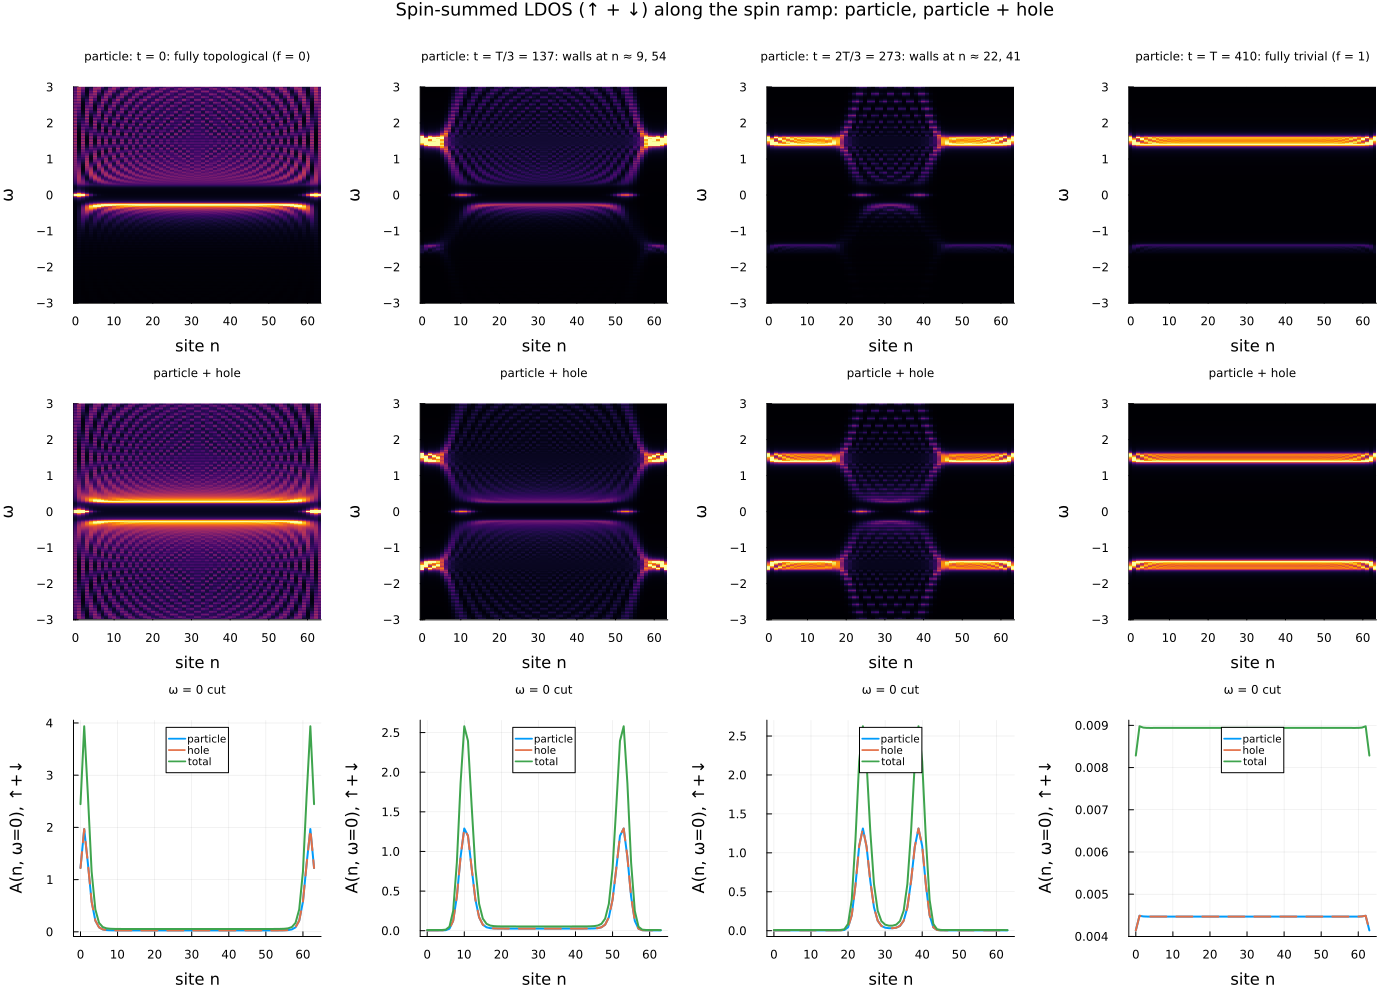

In [11]:
L = 6;  N = 2^L
ω = range(-3, 3; length=601)

cases = ldos_snapshots                                  # t = 0, T/3, 2T/3, T of the spin ramp

gr()
cmax(A) = sort(vec(A))[ceil(Int, 0.995*length(A))]      # colour scale: 99.5th percentile
hp = Plots.Plot[]; ht = Plots.Plot[]; cuts = Plots.Plot[]
i0 = argmin(abs.(ω))
for (name, f) in cases
    Ap, Ah = ldos(L, f; ω=ω)
    At = Ap .+ Ah
    @printf("%-40s max|A_h(ω) − A_p(−ω)| = %.1e\n", name, maximum(abs.(Ah .- reverse(Ap; dims=1))))
    push!(hp, heatmap(0:N-1, ω, Ap; c=:inferno, clims=(0, cmax(Ap)), colorbar=false,
                      xlabel="site n", ylabel="ω", title="particle: " * name, titlefontsize=8))
    push!(ht, heatmap(0:N-1, ω, At; c=:inferno, clims=(0, cmax(At)), colorbar=false,
                      xlabel="site n", ylabel="ω", title="particle + hole", titlefontsize=8))
    push!(cuts, plot(0:N-1, [Ap[i0, :] Ah[i0, :] At[i0, :]]; lw=[2 2 2], ls=[:solid :dash :solid],
                     label=["particle" "hole" "total"], legend=:top, legendfontsize=7,
                     xlabel="site n", ylabel="A(n, ω=0), ↑+↓", title="ω = 0 cut", titlefontsize=8))
end
p = plot(hp..., ht..., cuts...; layout=(3, length(cases)), size=(1400, 1000),
         plot_title="Spin-summed LDOS (↑ + ↓) along the spin ramp: particle, particle + hole", plot_titlefontsize=12,
         margin=4Plots.mm)
savefig(p, "msh_chain_ldos.png")
p

## 8. LDOS with TensorBinding's KPM routine

Section 7 diagonalizes the dense $4N\times4N$ matrix, which stops being feasible beyond $N\approx128$ sites.
TensorBinding's `get_ldos_spatial` uses the **kernel polynomial method (KPM)** instead. It expands
$\delta(\omega - H)$ in Chebyshev polynomials $T_n(\tilde H)$ of the rescaled Hamiltonian $\tilde H = (H - \text{center})/\text{scale}$,
evaluated directly on the MPO, and damps the expansion with a Jackson kernel. No dense matrix is ever built.

**Using it with `msh_chain`.**
- **Wrapping.** `get_ldos_spatial` takes a `TBHamiltonian`, not a bare MPO. `msh_tb(L, f)` builds the chain with `msh_chain`
  and wraps it with `spin_s`, `nambu_s` and `aux_side = :pre` set. The package's sector projections expect the site order
  `[nambu; spin; pos...]`, which is what `msh_chain` produces.
- **Sector selection.** `nambu_proj=true, proj_nambu=1` gives the particle sector (`2` for the hole sector).
  `spin_proj=true` sums over spin (add `proj_s=1` or `2` for a single spin).
- **Units.** The raw output is per rescaled energy and carries an extra $1/\pi$. Multiply by `π / H.scale` for the physical LDOS,
  which then integrates to 2 states per site (↑ + ↓), the same normalization as section 7.
- **`scale`.** `msh_tb` sets it from the bound $\|H_{\rm BdG}\| \le |\mu| + |J| + 2\sqrt{t^2+\alpha^2} + |\Delta|$ (≈ 18.8),
  so the package doesn't run its DMRG-based estimate.

**Resolution and cost.** The Jackson kernel broadens every peak by about $\pi\cdot\text{scale}/N_{\rm cheb}$.
The spectrum spans about ±16 but the superconducting gap is only 0.26, so resolving it takes $N_{\rm cheb}\approx 1000$ (resolution ≈ 0.06).
At $N = 64$ that is slower than dense diagonalization:

| `Ncheb` | resolution | mode | time (64 sites) |
|---|---|---|---|
| 128 | ≈ 0.46 | `:mpo` (whole chain in one pass) | ≈ 25 s |
| 1024 | ≈ 0.058 | `:mpo` | ≈ 5–11 min (texture-dependent) |
| 1024 | ≈ 0.058 | `:mps` (one recursion per site and spin) | ≈ 6 s per site |

The advantage is scaling: no $4N\times4N$ matrix is ever formed. `mode=:mps` with `x_groups` computes only the sites you ask for,
such as chain ends or domain walls.

**Exact check.** `kpm_exact` pushes the exact eigenpairs through the *same* Chebyshev formula (same kernel, `Ncheb` and normalization).
Any difference from `get_ldos_spatial` is therefore pure tensor-network arithmetic error, not broadening.

In [12]:
"""
    msh_tb(L, f; scale=nothing, model...) -> TBHamiltonian

Wrap the `msh_chain` BdG MPO as a TBHamiltonian for TensorBinding's KPM routines.
`scale` is the KPM half-bandwidth; by default a safe analytic bound on ‖H_BdG‖.
"""
function msh_tb(L, f; scale=nothing, t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8, model...)
    HB, sites = msh_chain(L, f; t, μ, α, Δ, J, model...)
    ns, ss = sites[1], sites[2]
    bound = abs(μ) + abs(J) + 2*sqrt(t^2 + α^2) + abs(Δ)        # ‖H_BdG‖ ≤ bound
    sc = something(scale, 1.05 * bound)
    return TB.TBHamiltonian(; L, N=2^L, sites, mpo=HB, geometry=i -> Float64[i],
                            scale=sc, center=0.0, spin_s=ss, nambu_s=ns, aux_side=:pre)
end

# Exact KPM reference with TensorBinding's own conventions (KPM_tk.jl: get_ldos_spatial):
#   A(x, ω) = Σ_n W[n, ω̃] μ_n(x) / (π² Ncheb √(1 − ω̃²)),   ω̃ = (ω − center)/scale,
#   μ_n(x)  = Σ_k w_k(x) T_{n−1}(Ẽ_k),   w_k(x) = spin-summed weight in the chosen Nambu sector.
# Returns the raw (package-unit) LDOS, Nω × N; multiply by π/scale for physical units.
function kpm_exact(H::TB.TBHamiltonian, Ncheb, ω; kernel=:jackson, proj_nambu=1)
    N = H.N
    E, U = eigen(Hermitian(dense(H.mpo, H.sites)))
    off = (proj_nambu - 1) * 2N                               # nambu block offset
    w = abs2.(U[off+1:off+N, :]) .+ abs2.(U[off+N+1:off+2N, :])   # N × 4N
    Ẽ = (E .- H.center) ./ H.scale
    T = [cos((n-1) * acos(clamp(e, -1, 1))) for n in 1:Ncheb, e in Ẽ]   # Ncheb × 4N
    μn = T * w'                                               # Ncheb × N
    ω̃ = (collect(ω) .- H.center) ./ H.scale
    W = TB._kpm_weight_matrix(Ncheb, ω̃; kernel=kernel)       # Ncheb × Nω
    A = (W' * μn) ./ (π^2 * Ncheb .* sqrt.(max.(1 .- ω̃.^2, eps())))
    A[abs.(ω̃) .>= 1, :] .= 0
    return A
end

kpm_exact (generic function with 1 method)

### 8a. LDOS snapshots of the spin ramp (`Ncheb = 1024`, whole chain)

The same four ramp snapshots as section 7 (`ldos_snapshots`). The full computation takes about half an hour (5–11 min per snapshot), so by default
this cell loads saved results from `msh_chain_ldos_kpm_ramp.jls`, written by this cell.
Set `RUN_FULL_KPM = true` to recompute.

- **Row 1:** particle + hole LDOS from `get_ldos_spatial` (`proj_nambu` omitted, so both Nambu sectors are summed).
- **Row 2:** $\omega = 0$ cut, overlaid with the exact KPM result (particle + hole sectors summed).

The broadening differs from section 7. Jackson broadening is roughly Gaussian with width ≈ 0.058, while section 7 uses a Lorentzian with
$\eta = 0.03$. Peak positions agree but peak heights don't, because the two methods broaden peaks differently.

loading saved results from msh_chain_ldos_kpm_ramp.jls
t = 0: fully topological (f = 0)         max|A_TB − A_exact| = 5.3e-06
t = T/3 = 137: walls at n ≈ 9, 54        max|A_TB − A_exact| = 3.8e-06
t = 2T/3 = 273: walls at n ≈ 22, 41      max|A_TB − A_exact| = 3.6e-06
t = T = 410: fully trivial (f = 1)       max|A_TB − A_exact| = 3.4e-05


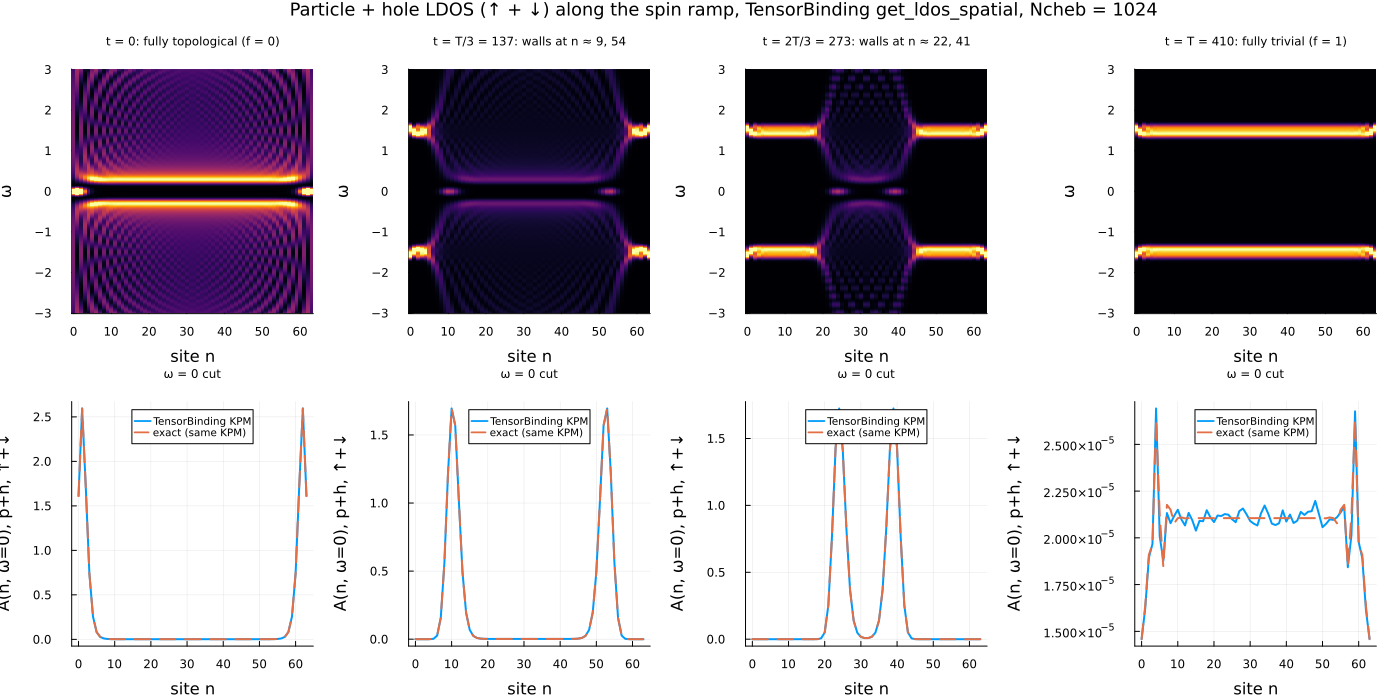

In [13]:
RUN_FULL_KPM = false
kpm_file = "msh_chain_ldos_kpm_ramp.jls"

using Serialization
kpm = if !RUN_FULL_KPM && isfile(kpm_file)
    println("loading saved results from $kpm_file")
    deserialize(kpm_file)
else
    L = 6;  N = 2^L;  Ncheb = 1024
    ω = range(-3, 3; length=241)
    cases = ldos_snapshots                                  # t = 0, T/3, 2T/3, T of the spin ramp
    results = []
    for (name, f) in cases
        H = msh_tb(L, f)
        A_tb = TB.get_ldos_spatial(H, Ncheb, ω; nambu_proj=true, spin_proj=true,
                                   maxdim=512, cutoff=1e-12) .* (π / H.scale)
        A_ex = (kpm_exact(H, Ncheb, ω; proj_nambu=1) .+ kpm_exact(H, Ncheb, ω; proj_nambu=2)) .* (π / H.scale)
        push!(results, (; name, A_tb, A_ex))
    end
    data = (; ω, L, Ncheb, results)
    serialize(kpm_file, data)
    data
end

let (; ω, L, Ncheb, results) = kpm, N = 2^L
    for r in results
        @printf("%-40s max|A_TB − A_exact| = %.1e\n", r.name, maximum(abs.(r.A_tb .- r.A_ex)))
    end
    cmax(A) = sort(vec(A))[ceil(Int, 0.995*length(A))]
    i0 = argmin(abs.(ω))
    heat = [heatmap(0:N-1, ω, r.A_tb; c=:inferno, clims=(0, cmax(r.A_tb)), colorbar=false,
                    xlabel="site n", ylabel="ω", title=r.name, titlefontsize=8) for r in results]
    cuts = [plot(0:N-1, [r.A_tb[i0, :] r.A_ex[i0, :]]; lw=[2 2], ls=[:solid :dash],
                 label=["TensorBinding KPM" "exact (same KPM)"], legend=:top, legendfontsize=7,
                 xlabel="site n", ylabel="A(n, ω=0), p+h, ↑+↓", title="ω = 0 cut", titlefontsize=8)
            for r in results]
    plot(heat..., cuts...; layout=(2, length(results)), size=(1400, 700), margin=4Plots.mm,
         plot_title="Particle + hole LDOS (↑ + ↓) along the spin ramp, TensorBinding get_ldos_spatial, Ncheb = $Ncheb",
         plot_titlefontsize=12)
end

## 9. Majorana zero modes and the fermion mode

Following `kitaev_tensor_network_V2.ipynb`, four steps turn the Majorana pair into one ordinary fermion using only MPS/MPO operations:

1. **Zero-mode subspace.** Penalized DMRG on the folded operator $K = H^2 + \eta^2$ finds the two states closest to $E = 0$.
   A third penalized state is a gap check: it should land at the bulk gap, not near zero.
2. **Localize.** Diagonalize the position operator $\hat X$ inside that two-state subspace. Its eigenvectors are the left and right Majoranas $\gamma_1, \gamma_2$.
3. **Self-conjugacy.** With particle–hole conjugation $C = \tau_x K$ ($K$ = complex conjugation), each $\hat X$ eigenvector satisfies
   $C\gamma = e^{i\theta}\gamma$. Multiplying by $e^{i\theta/2}$ makes $C\gamma = \gamma$ exactly.
4. **Pair.** $\psi_f = (\gamma_1 + i\gamma_2)/\sqrt2$, choosing the member with $E_f \ge 0$; its partner is $\bar\psi_f = C\psi_f$.

**Differences from the spinless Kitaev notebook.** The position qubits are `sites[3:end]`, and $C$ acts as $\tau_x$ on the Nambu site only (identity on spin).

**Numerical settings that matter** (each found by comparing with exact diagonalization):
- $K$'s spectrum spans about $10^{-4}$ to $230$ ($\|H\| \approx 15$ against a gap of $0.26$). ITensor's default local Krylov dimension (3) stalls at
  $\|H\psi\| \approx 0.2$; `eigsolve_krylovdim = 20` converges in about a second.
- `TB.build_K` needs `cutoff_K` $\le 10^{-14}$. The package default ($10^{-8}$) truncates part of the $\eta^2$ term.
- `refine_subspace` applies one inverse-iteration step $\psi \leftarrow (H-\sigma)^{-1}\psi$. DMRG on $K = H^2$ leaves a bulk admixture of amplitude
  $\sim 10^{-7}$–$10^{-6}$. That doesn't matter for energies or profiles, but it does matter for the charge difference of section 10 when the pair
  splitting is tiny.

In [14]:
using Random, Serialization, Logging

# KrylovKit warns ("ignoring imaginary component") at every DMRG/linsolve/TDVP step on these
# MPOs; the imaginary parts are round-off (~1e-9 of the weight). Show only errors from those calls.
quietly(f) = with_logger(f, ConsoleLogger(stderr, Logging.Error))

# ‖Hψ‖ computed exactly (tiny values are a cancellation of O(1) terms)
norm_Hψ(H, ψ) = norm(orthogonalize(apply(H, ψ; alg="naive", truncate=false), 1)[1])

# Dense state vector, ordered like dense(): nambu ⊗ spin ⊗ position (big-endian).
# Small L only; used only by the optional exact checks.
dense_vec(ψ, sites) = vec(Array(ITensors.@disable_warn_order(prod(ψ)), reverse(sites)...))

# Spin-summed particle |u|² and hole |v|² per site of an MPS on [nambu; spin; pos₁ … pos_L], without
# forming the 4·2^L vector: for site n, fix the position qubits to the bits of n (pos₁ most significant)
# and contract with the Nambu and spin tensors. Cost ~ 2^L · L · χ², so it works at any L.
function uv_profile(ψ, sites)
    ns, ss, pos = sites[1], sites[2], sites[3:end]
    L = length(pos);  u = zeros(2^L);  v = zeros(2^L)
    head = ψ[1] * ψ[2]
    for n in 0:2^L-1
        T = head
        for k in 1:L
            T *= ψ[k+2] * onehot(pos[k] => ((n >> (L - k)) & 1) + 1)
        end
        A = Array(T, ns, ss)
        u[n+1], v[n+1] = sum(abs2, A[1, :]), sum(abs2, A[2, :])
    end
    return u, v
end

apply_site(op, ψ, j) = (φ = copy(ψ); φ[j] = noprime(op * φ[j]); φ)

"""
    zero_mode_subspace(HB, sites; nzero=2, η=1e-2, ...) -> (ψs, E_sub, E_gap)

Penalized DMRG on K = H² + η² for `nzero` near-zero states, plus one more state as a gap check
(`E_gap` = its ‖Hψ‖, which should sit at the bulk gap).
"""
function zero_mode_subspace(HB, sites; nzero=2, η=1e-2, seed=1234,
                            nsweeps=20, maxdim=[10, 20, 50, 100, 200], cutoff=1e-14, cutoff_K=1e-14,
                            noise=[1e-6, 1e-7, 1e-8, 0.0], weight=10.0,
                            eigsolve_krylovdim=20, eigsolve_maxiter=3)
    K = TB.build_K(HB, sites, 0.0, η; cutoff_K)   # TB default cutoff_K = 1e-8 drops η²
    Random.seed!(seed)
    ψs = MPS[]
    for k in 1:nzero+1
        ψ0 = random_mps(sites; linkdims=10)
        _, ψ = quietly() do
            isempty(ψs) ? dmrg(K, ψ0; nsweeps, maxdim, cutoff, noise, eigsolve_krylovdim,
                               eigsolve_maxiter, outputlevel=0) :
                          dmrg(K, ψs, ψ0; weight, nsweeps, maxdim, cutoff, noise,
                               eigsolve_krylovdim, eigsolve_maxiter, outputlevel=0)
        end
        push!(ψs, ψ / norm(ψ))
    end
    ψgap = pop!(ψs)
    return ψs, [norm_Hψ(HB, ψ) for ψ in ψs], norm_Hψ(HB, ψgap)
end

"""
    refine_subspace(HB, ψs; σ=1e-3, nsweeps=6, cutoff=1e-20, maxdim=200) -> Vector{MPS}

One inverse-iteration step ψ ← (H − σ)⁻¹ψ / ‖·‖ per state (ITensorMPS.linsolve). It suppresses the
bulk admixture left by DMRG on K by ~gap/σ while keeping the pair (|E| ≪ σ) in the subspace.
Use it only when the pair splitting is far below σ (see section 10); a second step does not help.
"""
refine_subspace(HB, ψs; σ=1e-3, nsweeps=6, cutoff=1e-20, maxdim=200) =
    [(x = quietly(() -> ITensorMPS.linsolve(HB, ψ, ψ, -σ, 1.0; nsweeps, cutoff, maxdim)); x / norm(x)) for ψ in ψs]

refine_subspace (generic function with 1 method)

In [15]:
"""
    fermion_from_subspace(HB, sites, ψs; cutoff=1e-14) -> NamedTuple

Steps 2–4: localize with X̂ inside span(ψs) → γs (sorted by position), fix Cγ = γ, coupling
matrix H_ij = ⟨γ_i|H|γ_j⟩ = iA_ij, and for two states the fermion ψf = (γ₁ + iγ₂)/√2 (+E member)
with partner ψfbar = Cψf.
"""
function fermion_from_subspace(HB, sites, ψs; cutoff=1e-14)
    ns = sites[1]; pos = sites[3:end]; L = length(pos); nzero = length(ψs)

    # 2. localize with X̂ = 1 + Σ_k 2^(L−k) n_k,  n_k = |1⟩⟨1| on position qubit k (= site k+2)
    n1(k) = ITensor([0.0 0.0; 0.0 1.0], pos[k]', pos[k])
    S = [inner(a, b) for a in ψs, b in ψs]
    X = S + sum(2.0^(L - k) * [inner(a, apply_site(n1(k), b, k + 2)) for a in ψs, b in ψs]
                for k in 1:L)
    FX = eigen(Hermitian((X + X') / 2), Hermitian((S + S') / 2))
    combine(c) = (γ = c[1] * ψs[1];
                  for j in 2:nzero; γ = +(γ, c[j] * ψs[j]; cutoff); end;
                  γ / norm(γ))
    γs = [combine(FX.vectors[:, i]) for i in 1:nzero]

    # 3. self-conjugacy. X̂ is real and acts trivially on Nambu/spin, so it commutes with C;
    #    each X̂ eigenvector obeys Cγ = e^{iθ}γ, and e^{iθ/2}γ is exactly self-conjugate.
    τx = ITensor([0.0 1.0; 1.0 0.0], ns', ns)
    C(ψ) = (φ = dag(ψ); φ[1] = noprime(τx * φ[1]); φ)
    fixphase(γ) = exp(im * angle(inner(γ, C(γ))) / 2) * γ
    γs = fixphase.(γs)

    # Majorana couplings H_ij = ⟨γ_i|H|γ_j⟩ = i A_ij (A real antisymmetric)
    Hγ = [inner(a', HB, b) for a in γs, b in γs]

    out = (; centers=FX.values, γs, Hγ, C)
    nzero == 2 || return out

    # 4. pair into one fermion, positive-energy convention
    ψf = +(γs[1], im * γs[2]; cutoff);  ψf = ψf / norm(ψf)
    E_f = real(inner(ψf', HB, ψf))
    E_f < 0 && ((ψf, E_f) = (C(ψf), -E_f))
    return (; out..., ψf, ψfbar=C(ψf), E_f)
end

"""
    majorana_fermion(HB, sites; refine_σ=nothing, cutoff=1e-14, dmrg_kw...) -> NamedTuple

Full pipeline: `zero_mode_subspace` → (optional `refine_subspace` with σ = `refine_σ`)
→ `fermion_from_subspace`.  Returns ψs, E_sub, E_gap, centers, γs, Hγ, C and, for two zero
modes, ψf, ψfbar, E_f.
"""
function majorana_fermion(HB, sites; refine_σ=nothing, cutoff=1e-14, kw...)
    ψs, E_sub, E_gap = zero_mode_subspace(HB, sites; cutoff, kw...)
    isnothing(refine_σ) || (ψs = refine_subspace(HB, ψs; σ=refine_σ, cutoff=min(cutoff, 1e-20)))
    return (; ψs, E_sub, E_gap, fermion_from_subspace(HB, sites, ψs; cutoff)...)
end

majorana_fermion (generic function with 1 method)

### 9a. Example: Majoranas at the chain ends and at domain walls (about 1 min)

Two textures on 64 sites: all spins along $\hat z$ (Majoranas at the chain ends), and a topological middle half inside a trivial background
(Majoranas at the two domain walls). For each, the checks are:
- **zero-mode subspace:** $\|H\psi\|$ of the two DMRG states (≈ the pair splitting) and of the gap-check state (≈ 0.26);
- **normalization:** $\sum_n |\gamma_i(n)|^2 = 1$ and $\sum_n (|u(n)|^2 + |v(n)|^2) = 1$ for $\psi_f$ (the profiles are probabilities, so single-site peaks are small);
- **Majoranas:** centers $\langle x\rangle$, $\|C\gamma_i - \gamma_i\|$, orthonormality, and $\mathrm{Re}\,H_{ij} = 0$;
- **fermion:** $E_f = \langle\psi_f|H|\psi_f\rangle$ and $\langle\psi_f|\bar\psi_f\rangle = 0$;
- **exact comparison (optional, `check_exact`, small $L$ only):** the weight of $\gamma_1$, $\gamma_2$ and $\psi_f$ inside the exact zero-mode pair from dense diagonalization (should be 1 to about $10^{-12}$).

Everything except the optional exact comparison uses only MPS/MPO operations, so the cell runs unchanged for larger `L`
(set `check_exact = false` above $L \approx 8$). The profiles come from `uv_profile`, which fixes the position qubits to each site's bit string
instead of contracting the MPS into a dense vector.

The plot shows $|\gamma_i(x)|^2$ on a log scale and the particle and hole weight of $\psi_f$, both summed over spin.

── f = 0 (FM ẑ): Majoranas at the chain ends ──
  zero-mode subspace ‖Hψ‖ = [5.62e-8, 5.62e-8],  gap-check state ‖Hψ‖ = 0.255
  Majorana centers ⟨x⟩ (0-indexed) = [1.41, 61.59]
  ‖Cγᵢ − γᵢ‖ = [0.0, 5.7e-15],  max|⟨γᵢ|γⱼ⟩ − δᵢⱼ| = 1.1e-15,  max|Re H_ij| = 2.0e-24
  normalization Σₙ|γ₁(n)|², Σₙ|γ₂(n)|², Σₙ(|u|² + |v|²) of ψf = 1.000000000000, 1.000000000000, 1.000000000000
  E_f = ⟨ψf|H|ψf⟩ = 1.375e-14,  ⟨ψf|ψ̄f⟩ = 2.4e-14
  [exact] E_f = 1.668e-14;  weight in exact pair: γ₁ 1.000000000000, γ₂ 1.000000000000, ψf 1.000000000000
── domain f = 0 for 16 ≤ n < 48: Majoranas at the walls ──
  zero-mode subspace ‖Hψ‖ = [6.35e-7, 6.35e-7],  gap-check state ‖Hψ‖ = 0.259
  Majorana centers ⟨x⟩ (0-indexed) = [16.55, 46.45]
  ‖Cγᵢ − γᵢ‖ = [5.1e-10, 5.2e-10],  max|⟨γᵢ|γⱼ⟩ − δᵢⱼ| = 1.6e-15,  max|Re H_ij| = 5.3e-17
  normalization Σₙ|γ₁(n)|², Σₙ|γ₂(n)|², Σₙ(|u|² + |v|²) of ψf = 1.000000000000, 1.000000000000, 1.000000000000
  E_f = ⟨ψf|H|ψf⟩ = 3.319e-08,  ⟨ψf|ψ̄f⟩ = 3.6e-12
  [exact] E_f = 3.319e-08;  

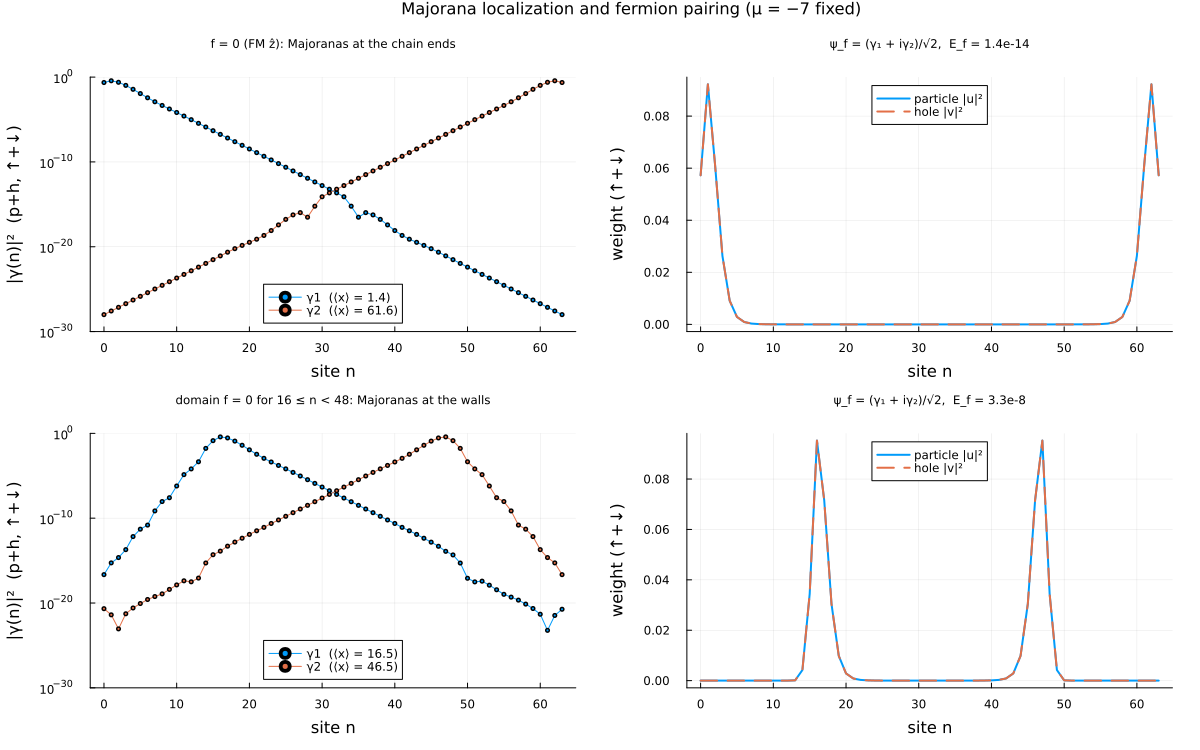

In [16]:
let L = 6, N = 2^L
    check_exact = L ≤ 8   # dense diagonalization of the 4·2^L matrix as a check; set false (or larger L) to skip
    cases = [("f = 0 (FM ẑ): Majoranas at the chain ends", n -> 0.0),
             ("domain f = 0 for $(N÷4) ≤ n < $(3N÷4): Majoranas at the walls",
              n -> N÷4 ≤ n < 3N÷4 ? 0.0 : 1.0)]
    panels = Plots.Plot[]
    for (name, f) in cases
        println("── ", name, " ──")
        HB, sites = msh_chain(L, f)
        r = majorana_fermion(HB, sites)
        @printf("  zero-mode subspace ‖Hψ‖ = %s,  gap-check state ‖Hψ‖ = %.3f\n",
                string(round.(r.E_sub, sigdigits=3)), r.E_gap)
        @printf("  Majorana centers ⟨x⟩ (0-indexed) = %s\n", string(round.(r.centers .- 1, digits=2)))
        @printf("  ‖Cγᵢ − γᵢ‖ = %s,  max|⟨γᵢ|γⱼ⟩ − δᵢⱼ| = %.1e,  max|Re H_ij| = %.1e\n",
                string(round.([norm(+(r.C(γ), -1 * γ)) for γ in r.γs], sigdigits=2)),
                maximum(abs.([inner(a, b) for a in r.γs, b in r.γs] - I)), maximum(abs, real.(r.Hγ)))
        wγ = [sum(uv_profile(γ, sites)) for γ in r.γs]   # |γ(n)|², particle + hole, ↑ + ↓
        u, v = uv_profile(r.ψf, sites)
        @printf("  normalization Σₙ|γ₁(n)|², Σₙ|γ₂(n)|², Σₙ(|u|² + |v|²) of ψf = %.12f, %.12f, %.12f\n",
                sum(wγ[1]), sum(wγ[2]), sum(u) + sum(v))
        @printf("  E_f = ⟨ψf|H|ψf⟩ = %.3e,  ⟨ψf|ψ̄f⟩ = %.1e\n", r.E_f, abs(inner(r.ψf, r.ψfbar)))
        if check_exact   # optional dense check, small L only
            E, U = eigen(Hermitian(dense(HB, sites)))
            Z = U[:, sortperm(abs.(E))[1:2]]
            inpair(ψ) = norm(Z' * dense_vec(ψ, sites))^2
            @printf("  [exact] E_f = %.3e;  weight in exact pair: γ₁ %.12f, γ₂ %.12f, ψf %.12f\n",
                    sort(abs.(E))[2], inpair(r.γs[1]), inpair(r.γs[2]), inpair(r.ψf))
        end

        pγ = plot(xlabel="site n", ylabel="|γ(n)|²  (p+h, ↑+↓)", yscale=:log10, ylims=(1e-30, 1),
                  title=name, titlefontsize=8, legend=:bottom)
        for (i, w) in enumerate(wγ)
            plot!(pγ, 0:N-1, max.(w, 1e-30); marker=:circle, markersize=2,
                  label="γ$i  (⟨x⟩ = $(round(r.centers[i] - 1, digits=1)))")
        end
        pf = plot(0:N-1, [u v]; lw=2, ls=[:solid :dash], label=["particle |u|²" "hole |v|²"],
                  xlabel="site n", ylabel="weight (↑+↓)", legend=:top,
                  title="ψ_f = (γ₁ + iγ₂)/√2,  E_f = $(round(r.E_f, sigdigits=2))", titlefontsize=8)
        push!(panels, pγ, pf)
    end
    plot(panels...; layout=(2, 2), size=(1200, 750), margin=5Plots.mm,
         plot_title="Majorana localization and fermion pairing (μ = −7 fixed)", plot_titlefontsize=11)
end

## 10. Charge difference between the logical states

The logical states $|0\rangle$ (mode empty) and $|1\rangle$ (mode filled) are BCS states that share the filled bulk and differ only in which member of the
zero-mode pair is occupied. Their BdG correlation matrices differ by exactly $|\psi_f\rangle\langle\psi_f| - |\bar\psi_f\rangle\langle\bar\psi_f|$, so **no bulk projector is
needed**. With $\psi_f = (u, v)$:

$$
\delta n(x) = n_1(x) - n_0(x) = \sum_\sigma |u_\sigma(x)|^2 - |v_\sigma(x)|^2,\qquad
\Delta Q = \sum_x \delta n(x) = \langle\psi_f|\tau_z|\psi_f\rangle .
$$

Here $\delta n$ counts electrons; the charge density is $-e\,\delta n$. $|1\rangle$ is the $+E$ member, which fixes the sign of $\Delta Q$.
$\Delta Q$ is not quantized: it comes from the overlap of the two Majoranas. Since $H$ contains $-\mu\hat N$, Feynman–Hellmann gives an independent check,
$\Delta Q = -\partial E_f/\partial\mu$.

**Geometry.** A centered segment of $\ell$ sites is topological ($f = 0$) and the rest is trivial ($f = 1$), at fixed $\mu = -7$. The Majoranas sit at the
two domain walls, so shrinking $\ell$ pushes them together.

**Accuracy and the refinement step.** $\Delta Q = \langle\psi_f|\tau_z|\psi_f\rangle$ is *first order* in any bulk admixture, because $\tau_z$ couples the zero mode
to bulk states. DMRG alone gives errors of about $10^{-8}$, which grow to $10^{-6}$ once $\Delta Q$ itself is tiny ($\ell \gtrsim 30$). One inverse-iteration
step (`refine_subspace`, $\sigma = 10^{-3}$) brings the error down to $10^{-10}$–$10^{-13}$, but only when the pair splitting is far below $\sigma$.
For $E \gtrsim \sigma/500$ the `linsolve` on $H-\sigma$ is poorly converged and adds error (up to $10^{-4}$), while DMRG alone is already accurate.
`majorana_pair_charge` therefore refines only when $\langle\psi_f|H|\psi_f\rangle < \sigma/500$. It judges the splitting by $\langle\psi_f|H|\psi_f\rangle$, which is
second order in the admixture, not by $\|H\psi\|$ of the DMRG states, which the admixture inflates.

In [17]:
# ΔQ = ⟨ψ|τ_z|ψ⟩ with τ_z on the Nambu site (identity on spin)
τz_on(ψ) = (φ = copy(ψ); s = siteind(ψ, 1);
            φ[1] = noprime(ITensor([1.0 0.0; 0.0 -1.0], s', s) * φ[1]); φ)
ΔQ_mode(ψ) = real(inner(ψ, τz_on(ψ)))

# Ψ component (nambu, spin, x) as a product MPS; x 0-indexed, pos_1 = most significant bit
function component_mps(sites, nb, σ, x)
    L = length(sites) - 2
    bits = [(x >> (L - k)) & 1 for k in 1:L]
    return MPS([onehot(sites[i] => v) for (i, v) in enumerate(vcat([nb, σ], bits .+ 1))])
end
# spin-summed δn(x) = Σ_σ |⟨p,σ,x|ψ⟩|² − |⟨h,σ,x|ψ⟩|², from MPS amplitudes (no dense vector)
δn_mode(ψ, sites) = [sum(abs2(inner(component_mps(sites, 1, σ, x), ψ)) -
                         abs2(inner(component_mps(sites, 2, σ, x), ψ)) for σ in 1:2)
                     for x in 0:2^(length(sites) - 2) - 1]

# centered segment of ℓ sites (0-indexed) in the topological (f = 0) configuration
segment(N, ℓ) = ((N - ℓ) ÷ 2):((N - ℓ) ÷ 2 + ℓ - 1)
f_segment(N, ℓ) = n -> n in segment(N, ℓ) ? 0.0 : 1.0

"""
    majorana_pair_charge(L, ℓ; refine_σ=1e-3, refine_below=refine_σ/500, gap_factor=2,
                         with_δn=false, model_kw...) -> NamedTuple

Zero-mode pair (penalized DMRG on K) → gap check → [one inverse-iteration step if the pair
splitting ⟨ψ_f|H|ψ_f⟩ < `refine_below`] → X̂ localization → Cγ = γ → ψ_f (+E member)
→ ΔQ = ⟨ψ_f|τ_z|ψ_f⟩.  `ΔQ_raw` is the value without refinement.  If the third penalized state
is not well above the pair, it warns and returns NaN.
"""
function majorana_pair_charge(L, ℓ; refine_σ=1e-3, refine_below=refine_σ/500, gap_factor=2.0,
                              cutoff=1e-20, with_δn=false, model_kw...)
    N = 2^L
    HB, sites = msh_chain(L, f_segment(N, ℓ); model_kw...)
    ψs, E_sub, E_gap = zero_mode_subspace(HB, sites; cutoff, cutoff_K=cutoff)
    if !(E_gap > gap_factor * maximum(E_sub))
        @warn "ℓ = $ℓ: third state ‖Hψ₃‖ = $(round(E_gap, sigdigits=4)) is not well above the pair " *
              "(‖Hψ‖ = $(round(maximum(E_sub), sigdigits=4))); returning NaN."
        return (ΔQ = NaN, ΔQ_raw = NaN, refined = false, E = NaN, E_next = E_gap, δn = nothing, centers = nothing)
    end
    r0 = fermion_from_subspace(HB, sites, ψs; cutoff)
    # ΔQ = ⟨ψ_f|τ_z|ψ_f⟩ is first order in the bulk admixture DMRG leaves (~1e-7–1e-6), because τ_z couples the zero
    # mode to bulk states (E_f is only second order). That matters once ΔQ itself is that small (large ℓ), so refine
    # there. Only when E_f ≪ σ: otherwise (H − σ)⁻¹ weights the ±E members unequally and linsolve converges poorly.
    refined = !isnothing(refine_σ) && abs(r0.E_f) < refine_below
    r = refined ?
        fermion_from_subspace(HB, sites, refine_subspace(HB, ψs; σ=refine_σ, cutoff); cutoff) : r0
    return (ΔQ = ΔQ_mode(r.ψf), ΔQ_raw = ΔQ_mode(r0.ψf), refined, E = r.E_f, E_next = E_gap,
            δn = with_δn ? δn_mode(r.ψf, sites) : nothing, centers = r.centers .- 1)
end

# Exact reference from the dense BdG matrix, plus the Feynman–Hellmann value −∂E_f/∂μ
function exact_pair_charge(L, ℓ; dμ=1e-4, μ=-7.0, model_kw...)
    N = 2^L; f = f_segment(N, ℓ)
    Eplus(μ) = (e = eigvals(Hermitian(reference(L, f; μ, model_kw...))); e[findfirst(>(0), e)])
    F = eigen(Hermitian(reference(L, f; μ, model_kw...)))
    i = findfirst(>(0), F.values)                        # +E state = |1⟩
    V = reshape(F.vectors[:, i], N, 2, 2)                # (x, spin, nambu)
    δn = vec(sum(abs2, V[:, :, 1]; dims=2) .- sum(abs2, V[:, :, 2]; dims=2))
    return (ΔQ = sum(δn), E = F.values[i], δn,
            ΔQ_FH = -(Eplus(μ + dμ) - Eplus(μ - dμ)) / (2dμ))
end

exact_pair_charge (generic function with 1 method)

### 10a. ΔQ versus segment length (first run about 10 min, then loaded from `msh_chain_charge.jls`)

$\ell = 2, 4, \dots, 48$ on 64 sites. Each point is compared with exact diagonalization and with $-\partial E_f/\partial\mu$; `[refined]` marks the points where the inverse-iteration step was applied. Set `RUN_CHARGE = true` to recompute.

In [18]:
RUN_CHARGE = false
charge_file = "msh_chain_charge.jls"

charge = if !RUN_CHARGE && isfile(charge_file)
    println("loading saved results from $charge_file")
    deserialize(charge_file)
else let L = 6, ℓs = collect(2:2:48)
    mps = [];  ex = [];  secs = Float64[]
    for ℓ in ℓs
        t = @elapsed (m = majorana_pair_charge(L, ℓ; with_δn = ℓ in (8, 16, 24)))
        push!(mps, m);  push!(ex, exact_pair_charge(L, ℓ));  push!(secs, t)
    end
    data = (; L, ℓs, mps, ex, secs)
    serialize(charge_file, data)
    data
end end

let (; L, ℓs, mps, ex, secs) = charge
    for (ℓ, m, e, t) in zip(ℓs, mps, ex, secs)
        @printf("ℓ = %2d:  ΔQ = %+.6e  exact %+.6e  (−∂E/∂μ %+.3e)  err %+.1e%s (DMRG only %+.1e)  %.0f s\n",
                ℓ, m.ΔQ, e.ΔQ, e.ΔQ_FH, m.ΔQ - e.ΔQ, m.refined ? " [refined]" : "", m.ΔQ_raw - e.ΔQ, t)
    end
    for (ℓ, m, e) in zip(ℓs, mps, ex)
        isnothing(m.δn) && continue
        @printf("ℓ = %2d:  max|δn_MPS − δn_exact| = %.1e,  Σδn = %+.6e,  ⟨ψ|τz|ψ⟩ = %+.6e\n",
                ℓ, maximum(abs, m.δn .- e.δn), sum(m.δn), m.ΔQ)
    end
end

loading saved results from msh_chain_charge.jls
ℓ =  2:  ΔQ = +7.214509e-01  exact +7.214509e-01  (−∂E/∂μ +7.215e-01)  err -3.7e-09 (DMRG only -3.7e-09)  6 s
ℓ =  4:  ΔQ = +5.190618e-01  exact +5.190618e-01  (−∂E/∂μ +5.191e-01)  err -3.0e-09 (DMRG only -3.0e-09)  6 s
ℓ =  6:  ΔQ = +2.565048e-01  exact +2.565048e-01  (−∂E/∂μ +2.565e-01)  err -1.3e-09 (DMRG only -1.3e-09)  6 s
ℓ =  8:  ΔQ = +1.123403e-01  exact +1.123403e-01  (−∂E/∂μ +1.123e-01)  err +3.8e-09 (DMRG only +3.8e-09)  7 s
ℓ = 10:  ΔQ = +5.012841e-02  exact +5.012842e-02  (−∂E/∂μ +5.013e-02)  err -8.4e-09 (DMRG only -8.4e-09)  6 s
ℓ = 12:  ΔQ = +2.232591e-02  exact +2.232592e-02  (−∂E/∂μ +2.233e-02)  err -1.2e-08 (DMRG only -1.2e-08)  6 s
ℓ = 14:  ΔQ = +9.629462e-03  exact +9.629467e-03  (−∂E/∂μ +9.629e-03)  err -4.5e-09 (DMRG only -4.5e-09)  6 s
ℓ = 16:  ΔQ = +4.043709e-03  exact +4.043733e-03  (−∂E/∂μ +4.044e-03)  err -2.3e-08 (DMRG only -2.3e-08)  6 s
ℓ = 18:  ΔQ = +1.674244e-03  exact +1.674243e-03  (−∂E/∂μ +1.674e-03)  e

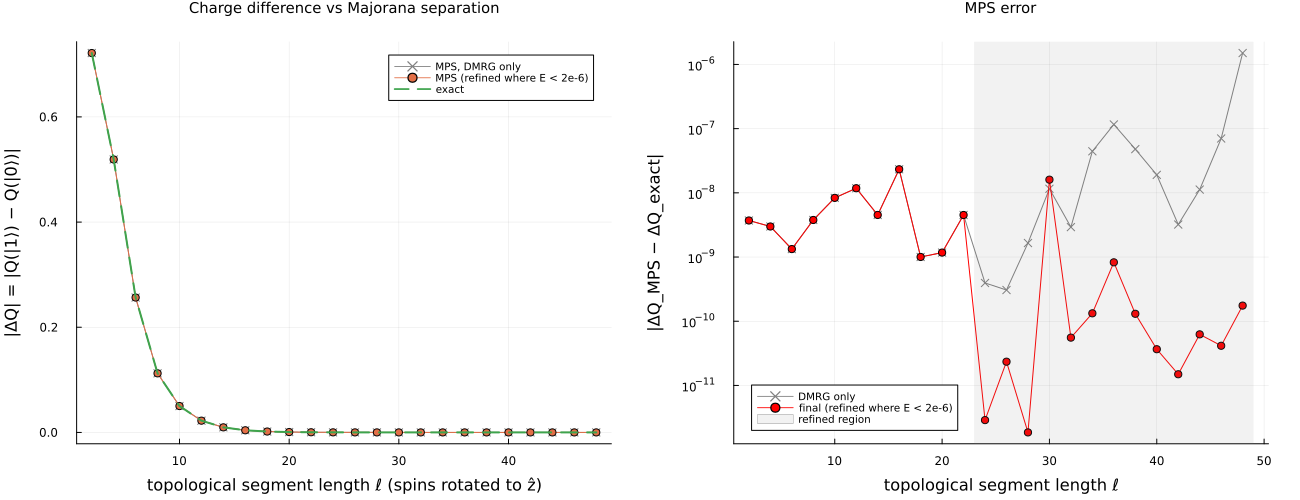

In [19]:
let (; ℓs, mps, ex) = charge
    # ΔQr ("DMRG only"): ψ_f built directly from the DMRG zero-mode states.
    # ΔQm ("refined"): the same, after one inverse-iteration step (H − σ)⁻¹ on those states, applied only where
    # E_f < σ/500 = 2e-6 (ℓ ≥ 24); identical to ΔQr elsewhere. See the comment in majorana_pair_charge.
    ΔQm = [m.ΔQ for m in mps];  ΔQr = [m.ΔQ_raw for m in mps]
    ΔQe = [e.ΔQ for e in ex]
    refined = [m.refined for m in mps]

    p1 = plot(ℓs, abs.(ΔQr); marker=:x, markersize=4, color=:gray, label="MPS, DMRG only")
    plot!(p1, ℓs, abs.(ΔQm); marker=:circle, markersize=4, label="MPS (refined where E < 2e-6)",
          xlabel="topological segment length ℓ (spins rotated to ẑ)", ylabel="|ΔQ| = |Q(|1⟩) − Q(|0⟩)|",
          title="Charge difference vs Majorana separation", titlefontsize=10, legend=:topright, legendfontsize=7)
    plot!(p1, ℓs, abs.(ΔQe); ls=:dash, lw=2, label="exact")

    # MPS error against exact diagonalization (log scale; floor at 1e-16 for exact zeros)
    p2 = plot(ℓs, max.(abs.(ΔQr .- ΔQe), 1e-16); yscale=:log10, yticks=10.0 .^ (-13:-5), marker=:x, markersize=4, color=:gray,
              label="DMRG only", xlabel="topological segment length ℓ", ylabel="|ΔQ_MPS − ΔQ_exact|",
              title="MPS error", titlefontsize=10, legend=:bottomleft, legendfontsize=7)
    plot!(p2, ℓs, max.(abs.(ΔQm .- ΔQe), 1e-16); marker=:circle, markersize=4, color=:red,
          label="final (refined where E < 2e-6)")
    vspan!(p2, [minimum(ℓs[refined]) - 1, maximum(ℓs) + 1]; color=:gray, alpha=0.1, label="refined region")
    plot(p1, p2; layout=(1, 2), size=(1300, 500), margin=6Plots.mm)
end


**Plot.** Left: $|\Delta Q|$ against $\ell$, from MPS (with and without refinement) and exact diagonalization.
The Feynman–Hellmann check $\Delta Q = -\partial E_f/\partial\mu$ is in the printed table above.
Right: the MPS error $|\Delta Q_{\rm MPS} - \Delta Q_{\rm exact}|$ on a log scale, for DMRG alone (gray) and
after the inverse-iteration step (red); the shaded region marks the segment lengths where the step is applied ($E_f < 2\times10^{-6}$).


## 11. Time-dependent ramp: moving the Majoranas by rotating spins

At $t = 0$ every spin points along $\hat z$ ($f = 0$, topological) and the Majoranas sit at the chain ends. Sites are then rotated one after another,
starting at both ends, into the in-plane antiferromagnetic texture ($f = 1$, trivial). The two domain walls move inward and carry the Majoranas toward the
center, stopping when $\ell_{\rm final}$ topological sites are left. This is the Kitaev notebook's "moving the MZMs" calculation, with $\mu(x,t)$ replaced by
spin rotation.

**Ramp (the CZ project's `algorithm_protocol` / `exchange_*` form):**

$$
f_n(t) = \mathrm{smoothstep}\!\left(\frac{t - t_0}{\texttt{rot\_T}} - \texttt{step\_T}\cdot k_n\right),\qquad
\mathrm{smoothstep}(\tau) = \sin^2(\pi\tau/2)\ \text{on}\ [0,1],
$$

with $k_n = \min(n, N-1-n)$ the distance from the nearer chain end; the central $\ell_{\rm final}$ sites never rotate. Each site turns over a time
`rot_T`, and consecutive sites start `step_T·rot_T` apart. The walls therefore move at $1/(\texttt{step\_T}\cdot\texttt{rot\_T})$ sites per unit time and are
about $1/\texttt{step\_T}$ sites wide. The CZ values are `rot_T = 100`, `step_T = 0.1`. `SpinRamp` and `f_nt` are defined in section 7,
where the LDOS plots use snapshots of the same ramp with `ℓ_final = 0`.

**$H(t)$.** The static part (hopping, $\mu$, Rashba, pairing) is built once with `msh_chain(...; J = 0)`. The exchange $J\,\mathbf S_n(t)\cdot\boldsymbol\sigma$
is rebuilt exactly at each time from three diagonal MPOs, entering the particle block as $\sigma_\alpha$ and the hole block as $-\sigma_\alpha^*$.

**What is evolved.** Only the fermion mode: $\Gamma_1(t) - \Gamma_0(t) = |\psi_f(t)\rangle\langle\psi_f(t)| - |C\psi_f(t)\rangle\langle C\psi_f(t)|$ at all times
(the shared bulk cancels, and $U(t)$ commutes with $C$). So

$$
\delta n(x,t) = \sum_\sigma |u_\sigma(x,t)|^2 - |v_\sigma(x,t)|^2,\qquad \Delta Q(t) = \langle\psi_f(t)|\tau_z|\psi_f(t)\rangle,
$$

with $\psi_f$ evolved by TDVP, $i\partial_t\psi = H(t)\psi$. At $t = T$ the weight of $\psi_f$ outside the instantaneous $\pm E$ doublet is the
**leakage** into bulk quasiparticles, the non-adiabatic error. $|1\rangle$ is the state whose mode ends in $+E$; if $\psi_f$ ends in $-E$ the roles swap
($\psi_f \to C\psi_f$, which flips the sign of $\Delta Q$).

In [20]:
# smoothstep, SpinRamp, n_rot, rot_order, f_nt, duration, wall_speed and wall_L are defined in section 7.

"""
    RampHamiltonian(L, p; J=5.8, φ=π/2, model_kw...)

Callable: `R(t)` returns the BdG MPO H(t) = H_static + exchange(t).  H_static is built once
with `msh_chain(...; J=0)`; the exchange is rebuilt exactly (diag_mpo_exact) at each time,
σ_α in the particle block and −σ_α* in the hole block.  `dense_H(R, t)` is the dense reference.
"""
struct RampHamiltonian
    L::Int; p::SpinRamp; J::Float64; φ::Float64; model_kw
    H_static::MPO; sites::Vector{<:Index}
end
function RampHamiltonian(L, p::SpinRamp; J=5.8, φ=π/2, model_kw...)
    H_static, sites = msh_chain(L, n -> 0.0; J=0.0, φ, model_kw...)
    return RampHamiltonian(L, p, J, φ, model_kw, H_static, sites)
end
f_at(R::RampHamiltonian, t) = n -> f_nt(R.p, n, t)

function (R::RampHamiltonian)(t; cutoff=1e-14)
    ns, ss, pos = R.sites[1], R.sites[2], R.sites[3:end]
    S = spin_texture(f_at(R, t); φ=R.φ)
    Svals = [S(n) for n in 0:2^R.L-1]
    H = R.H_static
    for (k, σ) in enumerate((σx, σy, σz))
        v = [R.J * s[k] for s in Svals]
        maximum(abs, v) > 1e-14 || continue
        D = diag_mpo_exact(v, pos)
        H = +(H, TB.prepend_nambu(TB.prepend_spin(D, ss, σ), ns, :Pp),
                 TB.prepend_nambu(TB.prepend_spin(D, ss, -conj(σ)), ns, :Ph); cutoff)
    end
    return H
end
dense_H(R::RampHamiltonian, t) = reference(R.L, f_at(R, t); J=R.J, φ=R.φ, R.model_kw...)

dense_H (generic function with 1 method)

**Check $H(t)$.** The MPO should match the dense reference to round-off at every time. The printout also shows the CZ ramp's rotation profile halfway
through: fully rotated sites near the ends, a wall about 10 sites wide, and unrotated sites in the middle.

In [21]:
let L = 6, p = SpinRamp(N=2^L), R = RampHamiltonian(L, p), T = duration(p)
    @printf("CZ ramp: %d sites rotated per side, ℓ_final = %d, T = %.0f, wall speed = %.2f sites per unit time\n",
            n_rot(p), p.ℓ_final, T, wall_speed(p))
    for t in (0.0, T / 3, 2T / 3, T)
        @printf("  t = %6.1f: ‖H_MPO − H_dense‖ = %.1e,  χ(H) = %d\n",
                t, norm(dense(R(t), R.sites) - dense_H(R, t)), maxlinkdim(R(t)))
    end
    println("f_n(t = 150) = ", round.([f_nt(p, n, 150.0) for n in 0:p.N-1], digits=2))
end

CZ ramp: 30 sites rotated per side, ℓ_final = 4, T = 390, wall speed = 0.10 sites per unit time
  t =    0.0: ‖H_MPO − H_dense‖ = 1.2e-12,  χ(H) = 5
  t =  130.0: ‖H_MPO − H_dense‖ = 4.9e-12,  χ(H) = 12
  t =  260.0: ‖H_MPO − H_dense‖ = 3.4e-12,  χ(H) = 12
  t =  390.0: ‖H_MPO − H_dense‖ = 1.3e-12,  χ(H) = 10
f_n(t = 150) = [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.98, 0.9, 0.79, 0.65, 0.5, 0.35, 0.21, 0.1, 0.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.02, 0.1, 0.21, 0.35, 0.5, 0.65, 0.79, 0.9, 0.98, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [22]:
# instantaneous ±E doublet of an MPO Hamiltonian: ψ₊, ψ₋, E₊ (2×2 Ritz in the refined DMRG pair)
function final_branches(H, sites; refine_σ=1e-3)
    ψs, _, _ = zero_mode_subspace(H, sites; cutoff=1e-20, cutoff_K=1e-20)
    ψs = refine_subspace(H, ψs; σ=refine_σ)
    S  = [inner(a, b) for a in ψs, b in ψs]
    Hs = [inner(a', H, b) for a in ψs, b in ψs]
    F  = eigen(Hermitian((Hs + Hs') / 2), Hermitian((S + S') / 2))
    mk(c) = (ψ = +(c[1] * ψs[1], c[2] * ψs[2]; cutoff=1e-20); ψ / norm(ψ))
    return mk(F.vectors[:, 2]), mk(F.vectors[:, 1]), F.values[2]
end

"""
    run_spin_ramp(R; dt=0.1, nsnap=200, maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30) -> NamedTuple

1. ψ_f(0) from the t = 0 Hamiltonian (zero-mode pair + one refinement step, localization,
   Cγ = γ, pairing).
2. TDVP with H frozen at the midpoint of each step.  reverse_step = true is required: the package
   default (false) skips TDVP's backward sub-steps and gives wrong dynamics.
3. At t = T: overlaps with the instantaneous ±E doublet → leakage 1 − p₊ − p₋.
Returns ΔQ(t) and `nsnap + 1` snapshots of ψ_f.
"""
function run_spin_ramp(R::RampHamiltonian; dt=0.1, nsnap=200, maxdim=64, cutoff=1e-20,
                       tol=1e-12, krylovdim=30)
    T = duration(R.p); sites = R.sites
    nsteps = round(Int, T / dt); dt = T / nsteps
    r0 = majorana_fermion(R(0.0), sites; refine_σ=1e-3, cutoff=1e-20, cutoff_K=1e-20)
    states = quietly() do
        TB.evolve_with_tdvp_timedep(t -> R(t), r0.ψf, nsteps, dt;
                                    maxdim, cutoff, tol, krylovdim, reverse_step=true)
    end
    ψ₊, ψ₋, E₊ = final_branches(R(T), sites)
    ψT = states[end]
    p₊, p₋ = abs2(inner(ψ₊, ψT)), abs2(inner(ψ₋, ψT))
    σ = p₋ > p₊ ? -1 : 1
    σ == -1 && ((p₊, p₋) = (p₋, p₊))
    idx = unique(round.(Int, range(1, nsteps + 1; length=nsnap + 1)))
    return (; T, dt, E0 = r0.E_f, leak = 1 - p₊ - p₋, p_wrong = p₋, E₊,
            ΔQ_final = σ * ΔQ_mode(ψT), ΔQ_adiabatic = ΔQ_mode(ψ₊),
            times = (idx .- 1) .* dt, ΔQ_t = [σ * ΔQ_mode(states[i]) for i in idx],
            snapshots = states[idx], σ, maxχ = maximum(maxlinkdim, states))
end

# Exact reference: dense 4N×4N BdG, same midpoint propagator exp(−iH(t + dt/2)dt), same
# initial pairing and end-of-ramp analysis.  Returns ΔQ(t) and the dense ψ_f at the same samples.
function run_spin_ramp_exact(R::RampHamiltonian; dt=0.1, nsnap=200)
    T = duration(R.p); N = 2^R.L
    nsteps = round(Int, T / dt); dt = T / nsteps
    τz = vcat(ones(2N), -ones(2N))
    Cd(v) = vcat(conj(v[2N+1:end]), conj(v[1:2N]))
    F0 = eigen(Hermitian(dense_H(R, 0.0)))
    V  = F0.vectors[:, sortperm(abs.(F0.values))[1:2]]
    FX = eigen(Hermitian(V' * Diagonal(float.(repeat(0:N-1, 4))) * V))
    γ  = [V * FX.vectors[:, j] for j in 1:2]
    γ  = [g * exp(im * angle(dot(g, Cd(g))) / 2) for g in γ]
    ψ  = (γ[1] + im * γ[2]) / norm(γ[1] + im * γ[2])
    real(dot(ψ, dense_H(R, 0.0) * ψ)) < 0 && (ψ = Cd(ψ))
    idx = Set(round.(Int, range(1, nsteps + 1; length=nsnap + 1)))
    ΔQ_t = Float64[]; ψ_t = Vector{ComplexF64}[]
    rec() = (push!(ΔQ_t, real(dot(ψ, τz .* ψ))); push!(ψ_t, copy(ψ)))
    1 in idx && rec()
    for k in 1:nsteps
        ψ = exp(-im * dt * Hermitian(dense_H(R, (k - 0.5) * dt))) * ψ
        (k + 1) in idx && rec()
    end
    F = eigen(Hermitian(dense_H(R, T)))
    i₊ = findfirst(>(0), F.values)
    p₊, p₋ = abs2(dot(F.vectors[:, i₊], ψ)), abs2(dot(F.vectors[:, i₊ - 1], ψ))
    σ = p₋ > p₊ ? -1 : 1
    σ == -1 && ((p₊, p₋) = (p₋, p₊))
    return (; leak = 1 - p₊ - p₋, p_wrong = p₋, ΔQ_final = σ * real(dot(ψ, τz .* ψ)),
            ΔQ_t = σ .* ΔQ_t, ψ_t, σ)
end

"""
    adiabatic_reference(R, t) -> (ΔQ_ad, E_gap)

ΔQ of the instantaneous +E state of H(t) and the bulk gap (third smallest |E|), from the dense
matrix.  The pair is the two levels with the smallest |E|.  While the Majoranas are far apart its
splitting falls below round-off and the two members are numerically degenerate, so "the +E state"
would be an arbitrary mix with an O(1) ΔQ; the true value (≈ ℓ·E) is then < 1e-9 and is set to 0.
"""
function adiabatic_reference(R::RampHamiltonian, t)
    N = 2^R.L
    F = eigen(Hermitian(dense_H(R, t)))
    o = sortperm(abs.(F.values));  pair = o[1:2]
    E₊ = maximum(F.values[pair])
    ΔQad = E₊ < 1e-11 ? 0.0 :
           (v = F.vectors[:, pair[argmax(F.values[pair])]]; sum(abs2, v[1:2N]) - sum(abs2, v[2N+1:end]))
    return ΔQad, abs(F.values[o[3]])
end

adiabatic_reference (generic function with 1 method)

### 11a. The CZ ramp on 64 sites (first run about 4 min, then loaded from `msh_chain_ramp.jls`)

TDVP for $\psi_f$ and the exact dense evolution, with the CZ values `rot_T = 100`, `step_T = 0.1` ($T = 390$). The saved data are the derived quantities
(times, $\Delta Q(t)$, the profiles $|\psi_f(x,t)|^2$ and $\delta n(x,t)$), not the MPS snapshots. Set `RUN_RAMP = true` to recompute, for example after
changing `ramp_params`.

In [23]:
RUN_RAMP = false
ramp_file = "msh_chain_ramp.jls"
ramp_params = (L = 6, rot_T = 100.0, step_T = 0.1, ℓ_final = 4)      # CZ values

ramp = if !RUN_RAMP && isfile(ramp_file)
    println("loading saved results from $ramp_file")
    deserialize(ramp_file)
else let (; L, rot_T, step_T, ℓ_final) = ramp_params, N = 2^L
    p = SpinRamp(; N, rot_T, step_T, ℓ_final)
    R = RampHamiltonian(L, p)
    t_mps = @elapsed (mps = run_spin_ramp(R))
    t_ex  = @elapsed (ex = run_spin_ramp_exact(R))
    W  = reduce(hcat, [sum(uv_profile(ψ, R.sites)) for ψ in mps.snapshots])            # |ψ_f(x,t)|²
    δn = reduce(hcat, [-(uv_profile(ψ, R.sites)...) for ψ in mps.snapshots]) .* mps.σ   # n₁ − n₀
    δn_ex = reduce(hcat, [(V = reshape(v, N, 2, 2);
                           vec(sum(abs2, V[:, :, 1]; dims=2) .- sum(abs2, V[:, :, 2]; dims=2)))
                          for v in ex.ψ_t]) .* ex.σ
    ΔQ_ad = [first(adiabatic_reference(R, t)) for t in mps.times]
    data = (; params = ramp_params, p, mps = Base.structdiff(mps, (; snapshots = nothing)),
            ex = Base.structdiff(ex, (; ψ_t = nothing)), W, δn, δn_ex, ΔQ_ad, t_mps, t_ex)
    serialize(ramp_file, data)
    data
end end

let (; mps, ex, δn, δn_ex, t_mps, t_ex) = ramp
    @printf("MPS:   E(0) = %.1e, leak = %.3e, wrong branch = %.1e, ΔQ(T) = %+.6f (adiabatic %+.6f), χ ≤ %d, %.0f s\n",
            mps.E0, mps.leak, mps.p_wrong, mps.ΔQ_final, mps.ΔQ_adiabatic, mps.maxχ, t_mps)
    @printf("exact: leak = %.3e, wrong branch = %.1e, ΔQ(T) = %+.6f, %.0f s\n",
            ex.leak, ex.p_wrong, ex.ΔQ_final, t_ex)
    @printf("max_t |ΔQ_MPS(t) − ΔQ_exact(t)| = %.1e,  max_{x,t} |δn_MPS − δn_exact| = %.1e\n",
            maximum(abs.(mps.ΔQ_t .- ex.ΔQ_t)), maximum(abs.(δn .- δn_ex)))
end

loading saved results from msh_chain_ramp.jls
MPS:   E(0) = 1.3e-14, leak = 2.143e-04, wrong branch = 3.7e-18, ΔQ(T) = +0.516615 (adiabatic +0.519062), χ ≤ 16, 172 s
exact: leak = 2.143e-04, wrong branch = 4.1e-27, ΔQ(T) = +0.516615, 56 s
max_t |ΔQ_MPS(t) − ΔQ_exact(t)| = 4.1e-07,  max_{x,t} |δn_MPS − δn_exact| = 2.6e-07


**Plot.**
- **Top left:** the rotation profile $f_n(t)$.
- **Top right:** the fermion mode $|\psi_f(x,t)|^2$ (particle + hole, summed over spin) on a log scale. It rides the two walls (dashed: wall centers) into the middle.
- **Bottom left:** the density difference $\delta n(x,t) = n_1 - n_0$. It stays exponentially small until the Majoranas approach each other.
- **Bottom right:** $\Delta Q(t)$ from TDVP, the exact evolution and the instantaneous adiabatic value. The wiggles of about $\pm 0.01$ mid-ramp are physical
  (interference with the small bulk component the ramp excites).

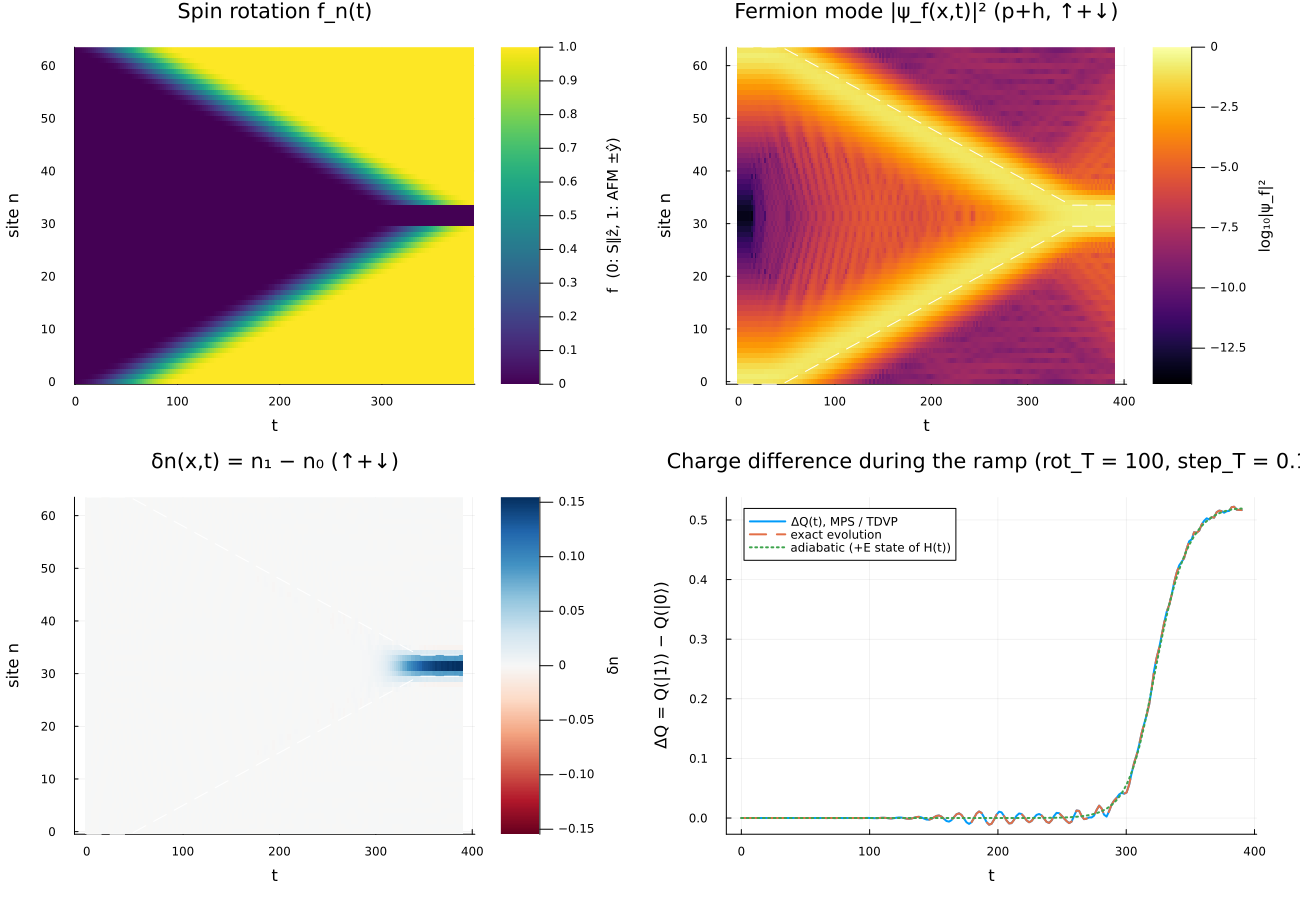

In [24]:
let (; p, mps, ex, W, δn, ΔQ_ad) = ramp, N = p.N
    ts = mps.times; xs = 0:N-1
    wl = [wall_L(p, t) for t in ts]; wr = N - 1 .- wl
    fmap = [f_nt(p, n, t) for n in xs, t in ts]
    pf = heatmap(ts, xs, fmap; c=:viridis, xlabel="t", ylabel="site n", clims=(0, 1),
                 colorbar_title="f  (0: S∥ẑ, 1: AFM ±ŷ)", title="Spin rotation f_n(t)")
    pψ = heatmap(ts, xs, log10.(max.(W, 1e-14)); c=:inferno, clims=(-14, 0), xlabel="t",
                 ylabel="site n", colorbar_title="log₁₀|ψ_f|²", title="Fermion mode |ψ_f(x,t)|² (p+h, ↑+↓)")
    lim = maximum(abs, δn)
    pδ = heatmap(ts, xs, δn; c=:RdBu, clims=(-lim, lim), xlabel="t", ylabel="site n",
                 colorbar_title="δn", title="δn(x,t) = n₁ − n₀ (↑+↓)")
    for q in (pψ, pδ)
        plot!(q, ts, wl; color=:white, ls=:dash, label="", legend=false)
        plot!(q, ts, wr; color=:white, ls=:dash, label="", ylims=(-0.5, N - 0.5))
    end
    pQ = plot(ts, mps.ΔQ_t; lw=2, label="ΔQ(t), MPS / TDVP", xlabel="t",
              ylabel="ΔQ = Q(|1⟩) − Q(|0⟩)", legend=:topleft,
              title=@sprintf("Charge difference during the ramp (rot_T = %g, step_T = %g)", p.rot_T, p.step_T))
    plot!(pQ, ts, ex.ΔQ_t; ls=:dash, lw=2, label="exact evolution")
    plot!(pQ, ts, ΔQ_ad; ls=:dot, lw=2, label="adiabatic (+E state of H(t))")
    plot(pf, pψ, pδ, pQ; layout=(2, 2), size=(1300, 900), margin=5Plots.mm)
end

## 12. How to adapt this notebook

**Change the spin texture.** Pass any `f(n)`:
```julia
f_wall(n) = n < 20 ? 1.0 : 0.0                    # single domain wall at n = 20
f_ramp(n) = clamp((n - 16) / 32, 0, 1)            # smooth rotation across the chain
HB, sites = msh_chain(6, f_wall)
```
For a time-dependent protocol, use `RampHamiltonian` (section 11), which rebuilds only the exchange part at each time step.

**Change the model parameters.** Use keyword arguments, e.g. `msh_chain(6, f; μ=-6.5, J=5.0, Δ=2.0)`. The same keywords go to `ldos`.
At fixed $\mu$, the 1D topological window for spins along $\hat z$ is
$\Delta^2 + (\mu+2t)^2 < J^2 < \Delta^2 + (\mu-2t)^2$ (Rashba does not shift these bounds).

**Bigger chains.**
- `msh_chain` works for large `L`: the MPO has a small bond dimension, and the exact diagonal MPOs cost $O(2^L)$ memory.
- `dense`, `reference` and `ldos` diagonalize a $4N\times4N$ matrix. Keep $L\le7$ for those.
- For longer chains, use the MPO methods directly: `majorana_fermion` / `majorana_pair_charge` for the zero modes and $\Delta Q$ (sections 9–10),
  `run_spin_ramp` for the time evolution (section 11), or the KPM LDOS of section 8 (`msh_tb` + `get_ldos_spatial`).
  `uv_profile` contracts the MPS site by site and works at any size; the `exact_*` references and `adiabatic_reference` are dense and only for checks at small $L$; `δn_mode` works at any size.
  Check against the dense `ldos` / `kpm_exact` at small $L$ first.

**Pitfalls.**
- Don't add terms with `add_superconductivity!`, `add_zeeman!` or `add_soc!` on top of this model. They use the $\tau_z$ hole block and a periodic Rashba bond (see section 2).
- TensorBinding's `:Sx/:Sy/:Sz` spin operators are $\sigma/2$. Use explicit Pauli matrices for $J\,\mathbf S\cdot\boldsymbol\sigma$.
- Build sharp, site-dependent profiles with `diag_mpo_exact`, not QTCI (`add_onsite!` with a function), for $L\ge 8$.

**Change the ramp.** `SpinRamp(N=N, rot_T=..., step_T=..., ℓ_final=...)` sets the CZ ramp; edit `f_nt` for a different rotation order, for example
rotating from one end only or moving a single wall. `ramp_params` in section 11a sets the run that is saved and plotted.

**More pitfalls (time-dependent and charge calculations).**
- Pass `reverse_step = true` to TensorBinding's TDVP routines. The default (`false`) gives wrong dynamics.
- `ΔQ` is first order in any bulk admixture of $\psi_f$. Use `refine_subspace` only when the pair splitting is far below $\sigma$ (section 10).
- When the Majoranas are far apart, their splitting is below round-off and "the $+E$ state" of a dense diagonalization is ill-defined. Use `adiabatic_reference`,
  not `findfirst(>(0), E)`.
- The saved `.jls` files are tied to the function and struct definitions in this notebook. If you change `SpinRamp` or the diagnostics, set the matching
  `RUN_*` flag to `true` once to regenerate them.

## Comparison with the dense Python reference

Loads `msh_compare_python.npz`, written by `ferromagnetic_spin_chain_msh_compare.ipynb` (dense NumPy BdG adapted
from `ferromagnetic_spin_chain_edit_ver2.ipynb`), and compares it with the functions of this notebook: one row per
quantity, max |Julia − Python| against a tolerance. Run that notebook first, in the same directory.

- Dense quantities (spectra, LDOS, `kpm_exact`, exact ΔQ and δn, exact ramp) should agree to round-off.
- DMRG/KPM/TDVP results (Majoranas, `get_ldos_spatial`, MPS ΔQ, TDVP ramp) agree to their truncation error.
  The `get_ldos_spatial`, MPS ΔQ and ramp rows use the `kpm`, `charge` and `ramp` results of sections 8a, 10
  and 11, and are skipped if those cells have not been run in this session.
- The Python code uses the opposite Rashba sign (−t − iασ_y on H[i+1, i], the paper's convention). Static
  quantities do not depend on it; the ramp rows use the Python run with α = −0.9, which is this notebook's model.
- The LDOS rows (`ldos_p_j`, `ldos_h_j`, `kpm1024_ph_j`) compare the four spin-ramp snapshots `ldos_snapshots`
  (t = 0, T/3, 2T/3, T), so the Python notebook must write its LDOS for the same snapshots.


In [25]:
using NPZ

py_file = "msh_compare_python.npz"      # written by ferromagnetic_spin_chain_msh_compare.ipynb
py = npzread(py_file)

# one row per comparison: max |Julia − Python| against a tolerance
cmp_rows = []
function check!(name, a, b; tol)
    d = maximum(abs.(a .- b))
    push!(cmp_rows, (; name, d, tol, ok = d <= tol))
    @printf("%-58s %9.1e  (tol %.0e)  %s\n", name, d, tol, d <= tol ? "✓" : "✗")
end

let L = 6, N = 2^L
    cases = last.(ldos_snapshots)                          # LDOS: the four spin-ramp snapshots of sections 7 and 8a
    names = ["t = 0", "t = T/3", "t = 2T/3", "t = T"]
    mzm_cases = [n -> 0.0, n -> N÷4 ≤ n < 3N÷4 ? 0.0 : 1.0]
    mzm_names = ["f = 0", "domain"]
    println("── dense BdG (msh_chain MPO) vs Python ──")
    E13 = map(py["sweep_f"]) do f
        HB, sites = msh_chain(L, n -> f)
        E = sort(abs.(eigvals(Hermitian(dense(HB, sites)))))
        [E[1], E[3]]
    end
    check!("f sweep |E|₁, |E|₃", reduce(hcat, E13)', py["sweep_E13"]; tol=1e-9)
    for (j, f) in enumerate(cases)
        Ap, Ah = ldos(L, f; ω=py["ldos_omega"])
        check!("Lorentzian LDOS particle, hole: $(names[j])", [Ap Ah], [py["ldos_p_$(j-1)"] py["ldos_h_$(j-1)"]]; tol=1e-9)
    end

    println("── KPM ──")
    if @isdefined(kpm) && kpm.Ncheb == 1024
        for (j, r) in enumerate(kpm.results)
            check!("get_ldos_spatial (8a), Ncheb = 1024, p+h: $(names[j])", r.A_tb, py["kpm1024_ph_$(j-1)"]; tol=1e-4)
        end
    else
        println("  (8a not run in this session: skipping get_ldos_spatial at Ncheb = 1024)")
    end

    println("── Majoranas (DMRG) ──")
    for (j, f) in enumerate(mzm_cases)
        HB, sites = msh_chain(L, f)
        r = majorana_fermion(HB, sites)
        check!("Majorana centers: $(mzm_names[j])", r.centers .- 1, py["mzm_centers_$(j-1)"]; tol=1e-4)
        check!("|γ₁|², |γ₂|² profiles: $(mzm_names[j])",
               reduce(hcat, [sum(uv_profile(γ, sites)) for γ in r.γs])', py["mzm_gamma_weight_$(j-1)"]; tol=1e-6)
        check!("E_f: $(mzm_names[j])", r.E_f, py["mzm_E_f_$(j-1)"][]; tol=1e-9)
    end

    println("── charge difference vs ℓ ──")
    ℓs = Int.(py["charge_ells"])
    ex = [exact_pair_charge(L, ℓ) for ℓ in ℓs]
    check!("exact ΔQ(ℓ)", [e.ΔQ for e in ex], py["charge_dQ"]; tol=1e-9)
    check!("exact δn(x) for every ℓ", reduce(hcat, [e.δn for e in ex])', py["charge_dn"]; tol=1e-9)
    if @isdefined(charge) && charge.ℓs == ℓs
        check!("MPS ΔQ(ℓ) (section 10)", [m.ΔQ for m in charge.mps], py["charge_dQ"]; tol=1e-6)
    else
        println("  (charge scan not run in this session: skipping the MPS values)")
    end

    println("── spin ramp (Python with the Julia Rashba sign) ──")
    if @isdefined(ramp)
        check!("exact ΔQ(t)", ramp.ex.ΔQ_t, py["ramp_julia_dQ_t"]; tol=1e-9)
        check!("exact leakage", ramp.ex.leak, py["ramp_julia_leak"][]; tol=1e-9)
        check!("MPS / TDVP ΔQ(t)", ramp.mps.ΔQ_t, py["ramp_julia_dQ_t"]; tol=1e-4)
    else
        println("  (ramp not run in this session: skipping)")
    end
end
@printf("\n%d of %d comparisons within tolerance\n", count(r -> r.ok, cmp_rows), length(cmp_rows))

── dense BdG (msh_chain MPO) vs Python ──
f sweep |E|₁, |E|₃                                           2.8e-14  (tol 1e-09)  ✓
Lorentzian LDOS particle, hole: t = 0                        8.7e-13  (tol 1e-09)  ✓
Lorentzian LDOS particle, hole: t = T/3                      7.5e-12  (tol 1e-09)  ✓
Lorentzian LDOS particle, hole: t = 2T/3                     1.2e-11  (tol 1e-09)  ✓
Lorentzian LDOS particle, hole: t = T                        3.8e-12  (tol 1e-09)  ✓
── KPM ──
get_ldos_spatial (8a), Ncheb = 1024, p+h: t = 0              5.3e-06  (tol 1e-04)  ✓
get_ldos_spatial (8a), Ncheb = 1024, p+h: t = T/3            3.8e-06  (tol 1e-04)  ✓
get_ldos_spatial (8a), Ncheb = 1024, p+h: t = 2T/3           3.6e-06  (tol 1e-04)  ✓
get_ldos_spatial (8a), Ncheb = 1024, p+h: t = T              3.4e-05  (tol 1e-04)  ✓
── Majoranas (DMRG) ──
Majorana centers: f = 0                                      2.0e-09  (tol 1e-04)  ✓
|γ₁|², |γ₂|² profiles: f = 0                                 3.3e-10  (tol 